# Exploracion de Steam_data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Cargamos los datos

In [2]:
df_raw = pd.read_csv("steam_data.csv", sep=";", encoding="utf-8-sig")
df_raw.shape

(62267, 4)

### Limpieza

In [3]:
df = df_raw.copy()
df["DateTime"] = pd.to_datetime(df["DateTime"], errors="coerce")
df["Players"] = pd.to_numeric(df["Players"], errors="coerce")
# Average Players se conserva tal cual (sin rellenar ni eliminar).
df["Fecha"] = df["DateTime"].dt.floor("D")
df["Año"] = df["DateTime"].dt.year
df["Mes"] = df["DateTime"].dt.month
df["Dia"] = df["DateTime"].dt.day
df["Hora"] = df["DateTime"].dt.hour
df_limpio = df.dropna(subset=["Game", "DateTime", "Players"]).copy()
diario_juego = (
    df_limpio.groupby(["Game", "Fecha"])["Players"]
    .mean()
    .reset_index()
    .sort_values(["Game", "Fecha"])
    .reset_index(drop=True)
)
print("filas:", len(df), "| juegos:", df["Game"].nunique())
print("rango:", df["Fecha"].min(), "->", df["Fecha"].max())
print("diario_juego:", diario_juego.shape)

filas: 62267 | juegos: 10
rango: 2007-09-19 00:00:00 -> 2026-10-05 00:00:00
diario_juego: (45269, 3)


### Datos de Twitch

`Mejoras/csv/twitch_games_monthly_historical.csv` recoge, para los mismos diez juegos, la audiencia mensual de Twitch: espectadores medios y pico, horas vistas y emitidas, y canales medios y pico. Steam mide jugadores simultáneos y Twitch mide espectadores: son dos señales distintas de la misma comunidad, así que sus escalas no son comparables directamente, pero sí lo son sus formas y sus cambios en el tiempo.

Dos advertencias antes de cruzar ambas fuentes:

- **Counter-Strike 2**: la serie de Twitch empieza en agosto de 2015, años antes del lanzamiento de CS2. Twitch mantuvo la misma página de directorio desde la época de CS:GO, así que esos meses describen la franquicia Counter-Strike, no a CS2 como juego concreto.
- **Among Us**: entre finales de 2018 y mediados de 2020 la audiencia de Twitch es prácticamente nula (hay meses con 0 espectadores), porque el juego todavía no había explotado. Cualquier cálculo que divida entre los espectadores de esos meses (porcentajes de cambio, ratios) necesita una protección explícita para no producir infinitos.

In [4]:
twitch_raw = pd.read_csv(
    "../Mejoras/csv/twitch_games_monthly_historical.csv",
    sep=";",
    encoding="utf-8-sig",
)

# Los nombres de columna y los valores de texto traen espacios sobrantes.
twitch_raw.columns = [columna.strip() for columna in twitch_raw.columns]
twitch_raw["Game"] = twitch_raw["Game"].str.strip()

columnas_numericas_twitch = [
    "AverageViewers",
    "PeakViewers",
    "HoursWatched",
    "HoursStreamed",
    "AverageChannels",
    "PeakChannels",
]
for columna in columnas_numericas_twitch:
    twitch_raw[columna] = pd.to_numeric(twitch_raw[columna], errors="coerce")

twitch_raw["DateTime"] = pd.to_datetime(twitch_raw["DateTime"], errors="coerce")
twitch_raw["Mes"] = twitch_raw["DateTime"].dt.to_period("M")

twitch_mensual = (
    twitch_raw.dropna(subset=["Game", "Mes"])
    .copy()
    .sort_values(["Game", "Mes"])
    .reset_index(drop=True)
)

print("filas:", len(twitch_mensual), "| juegos:", twitch_mensual["Game"].nunique())
print("rango:", twitch_mensual["Mes"].min(), "->", twitch_mensual["Mes"].max())

filas: 1283 | juegos: 10
rango: 2015-08 -> 2026-09


In [5]:
steam_mensual = (
    diario_juego.assign(Mes=diario_juego["Fecha"].dt.to_period("M"))
    .groupby(["Game", "Mes"])["Players"]
    .mean()
    .reset_index()
)

# Union externa: los meses presentes en una sola fuente quedan visibles como NaN
# en lugar de desaparecer, para poder detectar huecos de cobertura.
mensual_juego = steam_mensual.merge(
    twitch_mensual,
    on=["Game", "Mes"],
    how="outer",
    validate="one_to_one",
)

meses_solo_steam = mensual_juego["AverageViewers"].isna() & mensual_juego["Players"].notna()
meses_solo_twitch = mensual_juego["Players"].isna() & mensual_juego["AverageViewers"].notna()

print("mensual_juego:", mensual_juego.shape)
print("meses con Steam y sin Twitch:", int(meses_solo_steam.sum()))
print("meses con Twitch y sin Steam:", int(meses_solo_twitch.sum()))

mensual_juego: (1562, 11)
meses con Steam y sin Twitch: 279
meses con Twitch y sin Steam: 20


**Por que (Game, Mes)?** Steam se registra a diario (y, en los meses mas recientes, varias veces al dia), mientras que Twitch solo publica un agregado mensual. Para cruzar ambas senales sin inventar una resolucion que Twitch no tiene, el promedio diario de Steam (`diario_juego`) se reagrupa a mensual (`steam_mensual`) y se une con `twitch_mensual` por `(Game, Mes)`; ninguna de las dos series se fuerza a una granularidad mas fina de la que realmente mide.

In [7]:
cobertura_por_juego = pd.DataFrame({
    "Game": mensual_juego["Game"],
    "Solo Steam": meses_solo_steam,
    "Solo Twitch": meses_solo_twitch,
})
cobertura_por_juego["Coincide"] = ~(
    cobertura_por_juego["Solo Steam"] | cobertura_por_juego["Solo Twitch"]
)

resumen_cobertura = (
    cobertura_por_juego.groupby("Game")[["Coincide", "Solo Steam", "Solo Twitch"]]
    .sum()
    .assign(**{"Total de meses": lambda tabla_: tabla_.sum(axis=1)})
    .reset_index()
    .sort_values("Coincide", ascending=False)
)

tabla(resumen_cobertura, None)

,Game,Coincide,Solo Steam,Solo Twitch,Total de meses
1,Counter-Strike 2,134,44,0,178
2,Dota 2,134,48,0,182
9,Terraria,134,52,0,186
5,Project Zomboid,134,22,0,156
8,Team Fortress 2,134,88,0,222
6,Rust,134,21,0,155
7,Stardew Valley,130,1,0,131
3,Hollow Knight,118,1,15,134
4,PUBG,116,1,5,122
0,Among Us,95,1,0,96


- No se ha incorporado una segunda fuente (por ejemplo, fechas de lanzamiento o precios) en este cruce: las cuatro preguntas de la seccion de Twitch (correlacion, desfase, saltos virales, estacionalidad) se responden con jugadores de Steam y espectadores de Twitch unicamente. Si en el futuro se quisiera explicar, por ejemplo, un pico de audiencia por una rebaja de precio, haria falta anadir esa fuente; para las preguntas actuales, Twitch es suficiente.

### Utilidades compartidas (graficos, tablas y resumenes)

In [6]:
def barras(x, y, titulo, xlabel, ylabel, horizontal=False, color=None,
           figsize=(11, 5), rotacion=45, linea_cero=False):
    """Barras verticales u horizontales con el estilo comun."""
    plt.figure(figsize=figsize)
    if horizontal:
        plt.barh(x, y, color=color)
        plt.gca().invert_yaxis()
    else:
        plt.bar(x, y, color=color)
    plt.title(titulo)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    if not horizontal:
        plt.xticks(rotation=rotacion)
    if linea_cero:
        plt.axvline(0, color="black", linewidth=1)
    plt.grid(axis="x" if horizontal else "y", linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


def configurar(ax, titulo, xlabel, ylabel, eje_grid=True, rotacion_x=None):
    """Titulos, etiquetas y rejilla comunes para ejes line/scatter."""
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(eje_grid, linestyle="--", alpha=0.5)
    if rotacion_x is not None:
        ax.tick_params(axis="x", rotation=rotacion_x)


def tabla(datos, formato):
    """Muestra una tabla con formato numerico/fecha consistente."""
    if formato is None:
        display(datos)
    else:
        display(datos.style.format(formato))


def formato_porcentaje(valor):
    return f"{valor:.2f}".rstrip("0").rstrip(".") + " %"


def max_min(serie):
    """Devuelve (idxmax, idxmin) de una serie de promedios."""
    return serie.idxmax(), serie.idxmin()


def promedio_hora(marco, inicio=None, fin=None):
    """Promedio de Players por hora, opcionalmente en una ventana [inicio, fin]."""
    vista = marco
    if inicio is not None:
        vista = vista[vista["DateTime"] >= inicio]
    if fin is not None:
        vista = vista[vista["DateTime"] <= fin]
    return vista.groupby("Hora")["Players"].mean().reindex(range(24)).dropna()


def calcular_retencion(promedios):
    """Retencion por juego: ultimo promedio diario frente a su pico.

    Devuelve (comparacion ordenada, historiales por juego).
    """
    resultados = []
    historiales = {}
    for juego, historial in promedios.groupby("Game"):
        historial = historial.copy()
        fila_pico = historial.loc[historial["Players"].idxmax()]
        ultimo_registro = historial.iloc[-1]
        pico = fila_pico["Players"]
        porcentaje_conservado = (
            round(ultimo_registro["Players"] / pico * 100, 2) if pico > 0 else 0
        )
        historiales[juego] = (historial, pico)
        resultados.append(
            {
                "Juego": juego,
                "Fecha del pico": fila_pico["Fecha"],
                "Pico de jugadores": pico,
                "Última fecha": ultimo_registro["Fecha"],
                "Promedio actual de jugadores": ultimo_registro["Players"],
                "% conservado del pico": porcentaje_conservado,
                "% perdido": 100 - porcentaje_conservado,
            }
        )
    comparacion = (
        pd.DataFrame(resultados)
        .sort_values("% conservado del pico", ascending=False)
        .reset_index(drop=True)
    )
    return comparacion, historiales


def clasificar_desfase(juego, historial, desfases=range(-3, 4), umbral=0.3):
    """Mejor desfase entre jugadores y espectadores y su clasificacion.

    Un desfase positivo indica que Twitch se adelanta: los espectadores de
    un mes se relacionan con los jugadores de los meses posteriores.
    """
    pares = historial.dropna(subset=["Players", "AverageViewers"]).sort_values("Mes")
    if len(pares) < 5:
        return None
    jugadores = pares["Players"].to_numpy()
    espectadores = pares["AverageViewers"].to_numpy()
    mejor_desfase = None
    mejor_r = None
    for desfase in desfases:
        if desfase > 0:
            parte_steam, parte_twitch = jugadores[desfase:], espectadores[:-desfase]
        elif desfase < 0:
            parte_steam, parte_twitch = jugadores[:desfase], espectadores[-desfase:]
        else:
            parte_steam, parte_twitch = jugadores, espectadores
        if len(parte_steam) < 3:
            continue
        r = float(np.corrcoef(parte_steam, parte_twitch)[0, 1])
        if not np.isfinite(r):
            continue
        if mejor_r is None or abs(r) > abs(mejor_r):
            mejor_desfase, mejor_r = desfase, r
    if mejor_desfase is None:
        return None
    if abs(mejor_r) < umbral:
        clasificacion = "Sin relación clara"
    elif mejor_desfase > 0:
        clasificacion = "Twitch se adelanta"
    elif mejor_desfase < 0:
        clasificacion = "Steam se adelanta"
    else:
        clasificacion = "Sincronizados"
    return {
        "Juego": juego,
        "Desfase (meses)": mejor_desfase,
        "Correlación (r)": mejor_r,
        "Clasificación": clasificacion,
        "Meses comparados": len(pares),
    }


## 2. Forma y estructura

In [7]:
print(df_raw.shape)
print(df_raw.columns.tolist())
print(df_raw.dtypes)
df_raw.info()

(62267, 4)
['Game', 'DateTime', 'Players', 'Average Players']
Game                   str
DateTime               str
Players            float64
Average Players    float64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 62267 entries, 0 to 62266
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Game             62267 non-null  str    
 1   DateTime         62267 non-null  str    
 2   Players          60652 non-null  float64
 3   Average Players  14815 non-null  float64
dtypes: float64(2), str(2)
memory usage: 1.9 MB


## 3. Valores null y descripcion

In [8]:
print(df_raw.isna().sum())
print('Average Players con dato: '
      f'{df_raw["Average Players"].notna().mean():.1%}')
# Average Players se conserva tal cual: columna mayoritariamente vacia,
# sin rellenar ni eliminar; las preguntas actuales usan Players.
df_raw.describe(include="all")

Game                   0
DateTime               0
Players             1615
Average Players    47452
dtype: int64
Average Players con dato: 23.8%


,Game,DateTime,Players,Average Players
count,62267,62267,6.065200e+04,1.481500e+04
unique,10,8500,NaN,NaN
top,Team Fortress 2,2018-11-16 00:00:00,NaN,NaN
freq,8495,10,NaN,NaN
mean,NaN,NaN,2.365319e+05,1.923764e+05
std,NaN,NaN,3.667164e+05,2.790480e+05
min,NaN,NaN,1.000000e+00,2.615000e+03
25%,NaN,NaN,1.733350e+04,2.274000e+04
50%,NaN,NaN,5.428950e+04,5.750200e+04
75%,NaN,NaN,3.876900e+05,2.765325e+05


### Validacion de registros

Antes de pasar al analisis se comprueban duplicados, valores fuera de rango, el impacto real de la limpieza y la cobertura temporal por juego.

In [10]:
duplicados_exactos = df_raw.duplicated().sum()
duplicados_juego_fecha = df_raw.duplicated(subset=["Game", "DateTime"]).sum()

print(f"Filas duplicadas (fila completa): {duplicados_exactos}")
print(f"Filas duplicadas por (Game, DateTime): {duplicados_juego_fecha}")

Filas duplicadas (fila completa): 0
Filas duplicadas por (Game, DateTime): 0


- No aparecen filas duplicadas, ni por fila completa ni por la combinacion (Game, DateTime): cada lectura es unica y no hace falta deduplicar antes de limpiar.

In [11]:
jugadores_numerico = pd.to_numeric(df_raw["Players"], errors="coerce")
negativos_o_cero = int((jugadores_numerico <= 0).sum())

print(f"Filas con Players negativo o cero: {negativos_o_cero}")

Filas con Players negativo o cero: 0


- No hay valores de `Players` negativos ni iguales a cero: el rango de la columna es plausible y no requiere filtrado adicional.

In [12]:
filas_totales = len(df)
filas_tras_limpieza = len(df_limpio)
filas_eliminadas = filas_totales - filas_tras_limpieza

print(
    f"Filas eliminadas por dropna(Game, DateTime, Players): {filas_eliminadas} "
    f"({filas_eliminadas / filas_totales:.1%} del total)"
)

Filas eliminadas por dropna(Game, DateTime, Players): 1615 (2.6% del total)


- El `dropna` de la limpieza canonica elimina del orden del 2-3 % de las filas, correspondientes a registros sin valor de `Players`. Se decide mantener esa eliminacion: sin `Players` no hay forma de responder ninguna de las preguntas de la seccion de analisis para esa fila.

In [13]:
rango_por_juego = (
    df.groupby("Game")["Fecha"]
    .agg(**{"Primer registro": "min", "Ultimo registro": "max"})
    .reset_index()
    .sort_values("Primer registro")
)

tabla(rango_por_juego, {
    "Primer registro": lambda fecha: fecha.strftime("%d/%m/%Y"),
    "Ultimo registro": lambda fecha: fecha.strftime("%d/%m/%Y"),
})

,Game,Primer registro,Ultimo registro
8,Team Fortress 2,19/09/2007,05/10/2026
9,Terraria,15/05/2011,05/10/2026
2,Dota 2,22/09/2011,05/10/2026
1,Counter-Strike 2,30/11/2011,05/10/2026
5,Project Zomboid,01/11/2013,05/10/2026
6,Rust,01/12/2013,05/10/2026
7,Stardew Valley,01/12/2015,05/10/2026
3,Hollow Knight,01/12/2016,05/10/2026
4,PUBG,01/02/2017,05/10/2026
0,Among Us,16/11/2018,05/10/2026


- Counter-Strike 2 figura con datos desde 2011, doce años antes del lanzamiento del propio CS2 en 2023: la serie hereda el historial de la pagina de directorio de la franquicia Counter-Strike en Steam, no solo el periodo posterior al lanzamiento de CS2 (el mismo matiz que ya se documenta para los datos de Twitch de este juego). Cualquier conclusion que asuma "desde el lanzamiento de CS2" debe tener en cuenta esto.

In [14]:
registros_por_dia = df.groupby(["Game", "Fecha"]).size()
primer_dia_multiple = (
    registros_por_dia[registros_por_dia > 1]
    .reset_index(name="Registros")
    .groupby("Game")["Fecha"]
    .min()
    .rename("Primer dia con varios registros")
)

print("Primer dia con mas de un registro (muestreo horario) por juego:")
display(primer_dia_multiple.to_frame())

Primer dia con mas de un registro (muestreo horario) por juego:


,Primer dia con varios registros
Game,
Among Us,2026-09-05
Counter-Strike 2,2026-09-05
Dota 2,2026-09-05
Hollow Knight,2026-09-05
PUBG,2026-09-05
Project Zomboid,2026-09-05
Rust,2026-09-05
Stardew Valley,2026-09-05
Team Fortress 2,2026-09-05


- La frecuencia de muestreo no es constante: en el historial antiguo cada juego tiene un unico registro por dia, pero desde la fecha mostrada arriba empiezan a aparecer varios registros por dia (muestreo horario). Esto es una fuente de sesgo para cualquier media que mezcle filas de `df` sin pasar antes por `diario_juego` (un registro por juego y dia), porque los dias recientes pesarian mas solo por tener mas filas.

## 4. Vistazo a los datos

In [9]:
display(df_raw.head())
display(df_raw.tail())

,Game,DateTime,Players,Average Players
0,Among Us,2018-11-16 00:00:00,8.0,NaN
1,Among Us,2018-11-17 00:00:00,17.0,NaN
2,Among Us,2018-11-18 00:00:00,11.0,NaN
3,Among Us,2018-11-19 00:00:00,7.0,NaN
4,Among Us,2018-11-20 00:00:00,8.0,NaN


,Game,DateTime,Players,Average Players
62262,Terraria,2026-10-05 06:30:00,30841.0,NaN
62263,Terraria,2026-10-05 06:40:00,31138.0,NaN
62264,Terraria,2026-10-05 06:50:00,31317.0,NaN
62265,Terraria,2026-10-05 07:00:00,31385.0,38652.0
62266,Terraria,2026-10-05 07:10:00,31542.0,38652.0


In [10]:
print("n_games:", df_raw["Game"].nunique())
print(sorted(df_raw["Game"].unique()))
print("date min:", df["Fecha"].min())
print("date max:", df["Fecha"].max())

n_games: 10
['Among Us', 'Counter-Strike 2', 'Dota 2', 'Hollow Knight', 'PUBG', 'Project Zomboid', 'Rust', 'Stardew Valley', 'Team Fortress 2', 'Terraria']
date min: 2007-09-19 00:00:00
date max: 2026-10-05 00:00:00


## 5. Analisis

### ¿Cuales son los meses con mayor y menor cantidad de jugadores?

Mayor promedio: Marzo (263,412 jugadores)
Menor promedio: Septiembre (212,666 jugadores)


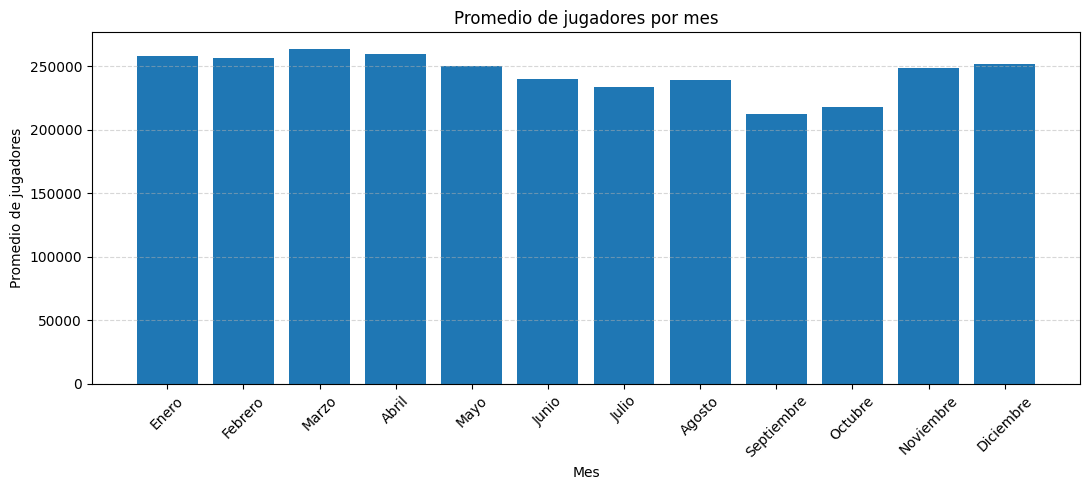

In [11]:
nombres_meses = [
    "Enero", "Febrero", "Marzo", "Abril", "Mayo", "Junio",
    "Julio", "Agosto", "Septiembre", "Octubre", "Noviembre", "Diciembre"
]

mes_promedio = df.groupby("Mes")["Players"].mean().reindex(range(1, 13))
mes_promedio = mes_promedio.dropna()

mes_maximo, mes_minimo = max_min(mes_promedio)

print(
    f"Mayor promedio: {nombres_meses[mes_maximo - 1]} "
    f"({mes_promedio.loc[mes_maximo]:,.0f} jugadores)"
)
print(
    f"Menor promedio: {nombres_meses[mes_minimo - 1]} "
    f"({mes_promedio.loc[mes_minimo]:,.0f} jugadores)"
)

barras(
    [nombres_meses[mes - 1] for mes in mes_promedio.index],
    mes_promedio.values,
    titulo="Promedio de jugadores por mes",
    xlabel="Mes",
    ylabel="Promedio de jugadores",
)

### ¿Cual es la hora con mayor y menor cantidad de jugadores?

Mayor promedio: a las 14:00 (310,887 jugadores)
Menor promedio: a las 01:00 (127,761 jugadores)


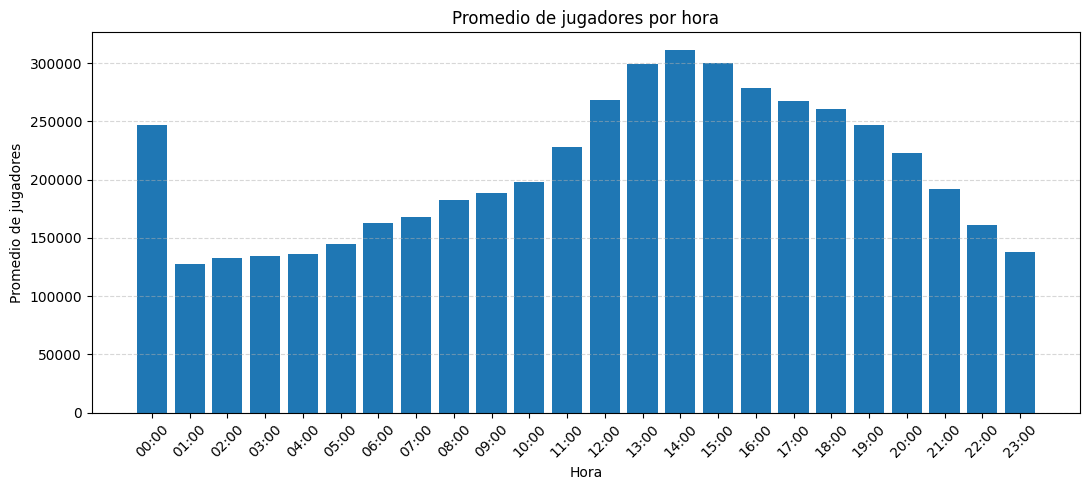

In [12]:
hora_promedio = promedio_hora(df)

hora_maxima, hora_minima = max_min(hora_promedio)

print(
    f"Mayor promedio: a las {hora_maxima:02d}:00 "
    f"({hora_promedio.loc[hora_maxima]:,.0f} jugadores)"
)
print(
    f"Menor promedio: a las {hora_minima:02d}:00 "
    f"({hora_promedio.loc[hora_minima]:,.0f} jugadores)"
)

barras(
    [f"{hora:02d}:00" for hora in hora_promedio.index],
    hora_promedio.values,
    titulo="Promedio de jugadores por hora",
    xlabel="Hora",
    ylabel="Promedio de jugadores",
)

- Hay que recalcar que el pico a las 00:00 se debe a que los datos mas antiguos de un mes no estan dividos por hora y solo tienen una entrada para todo el dia, el cual se coloca a las 00:00. Si no tuvieramos en cuenta los datos anteriores al 05/09 el resultado seria el siguiente:

Mayor promedio: a las 14:00 (310,887 jugadores)
Menor promedio: a las 01:00 (127,761 jugadores)


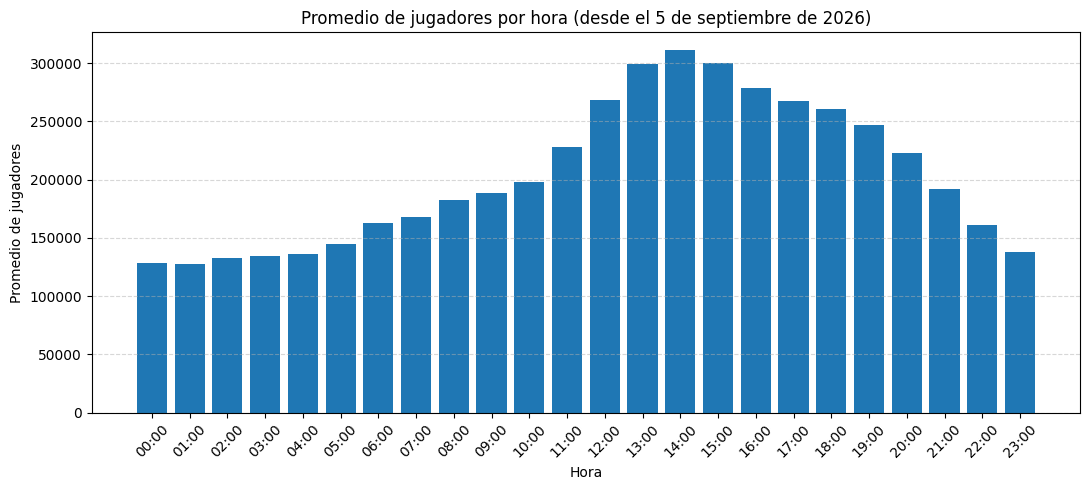

In [13]:
fecha_corte = pd.Timestamp("2026-09-05")
hora_reciente = promedio_hora(df, inicio=fecha_corte)

hora_maxima, hora_minima = max_min(hora_reciente)

print(
    f"Mayor promedio: a las {hora_maxima:02d}:00 "
    f"({hora_reciente.loc[hora_maxima]:,.0f} jugadores)"
)
print(
    f"Menor promedio: a las {hora_minima:02d}:00 "
    f"({hora_reciente.loc[hora_minima]:,.0f} jugadores)"
)

barras(
    [f"{hora:02d}:00" for hora in hora_reciente.index],
    hora_reciente.values,
    titulo="Promedio de jugadores por hora (desde el 5 de septiembre de 2026)",
    xlabel="Hora",
    ylabel="Promedio de jugadores",
)

### ¿Que juego ha tenido el pico mas grande de jugadores?

El máximo más alto fue de PUBG: 3,257,248 jugadores.


,Game,Máximo de jugadores
0,PUBG,3257248.0
1,Counter-Strike 2,1862531.0
2,Dota 2,1291328.0
3,Terraria,489886.0
4,Among Us,447476.0
5,Rust,262284.0
6,Team Fortress 2,253997.0
7,Stardew Valley,236614.0
8,Project Zomboid,124995.0
9,Hollow Knight,95655.0


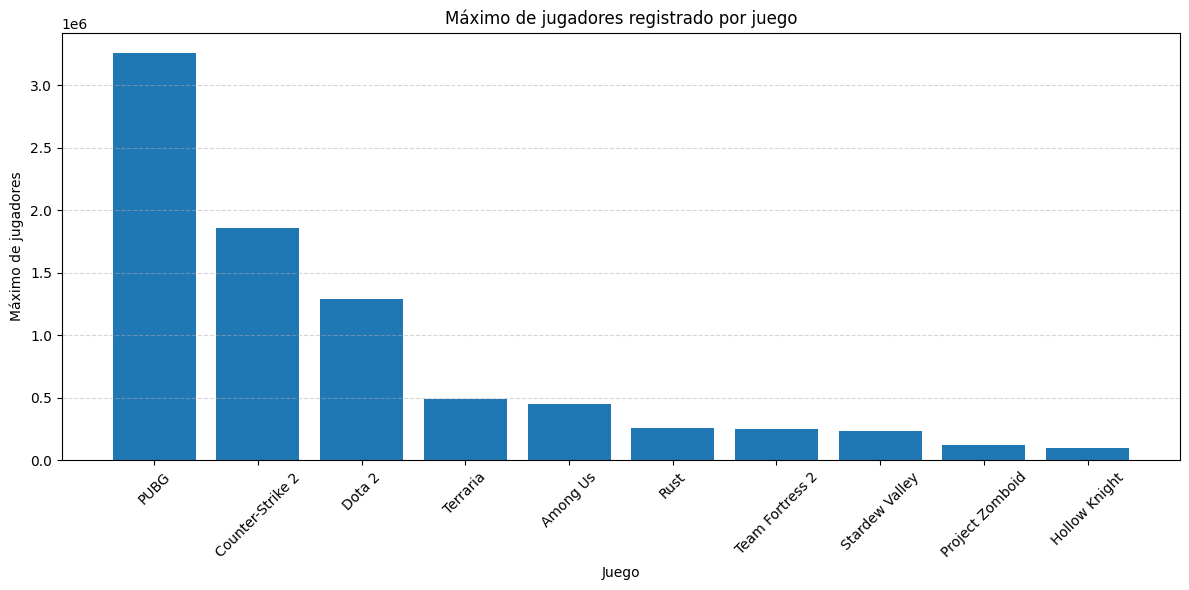

In [14]:
pico_maximos = (
    df.groupby("Game")["Players"]
    .max()
    .dropna()
    .sort_values(ascending=False)
)

print(f"El máximo más alto fue de {pico_maximos.index[0]}: "
      f"{pico_maximos.iloc[0]:,.0f} jugadores.")

tabla(
    pico_maximos.rename("Máximo de jugadores").to_frame().reset_index(),
    None,
)

barras(
    pico_maximos.index,
    pico_maximos.values,
    titulo="Máximo de jugadores registrado por juego",
    xlabel="Juego",
    ylabel="Máximo de jugadores",
    figsize=(12, 6),
)

### ¿Que juego ha retenido mejor a sus jugadores?

In [15]:
retencion_comparacion, retencion_historiales = calcular_retencion(diario_juego)

if retencion_comparacion.empty:
    print("No hay datos suficientes para comparar los juegos.")
else:
    retencion_mejor = retencion_comparacion.iloc[0]

    print(
        f"{retencion_mejor['Juego']} es el que mejor conserva su base: "
        f"mantiene el {retencion_mejor['% conservado del pico']:.2f} % "
        f"de su máximo diario."
    )

    tabla(retencion_comparacion, {
        "Pico de jugadores": "{:,.0f}",
        "Promedio actual de jugadores": "{:,.0f}",
        "% conservado del pico": formato_porcentaje,
        "% perdido": formato_porcentaje,
        "Fecha del pico": lambda fecha: fecha.strftime("%d/%m/%Y"),
        "Última fecha": lambda fecha: fecha.strftime("%d/%m/%Y"),
    })

Project Zomboid es el que mejor conserva su base: mantiene el 39.02 % de su máximo diario.


,Juego,Fecha del pico,Pico de jugadores,Última fecha,Promedio actual de jugadores,% conservado del pico,% perdido
0,Project Zomboid,09/08/2026,"124,995",05/10/2026,"48,773",39.02 %,60.98 %
1,Dota 2,06/03/2016,"1,291,328",05/10/2026,"437,260",33.86 %,66.14 %
2,Counter-Strike 2,12/04/2025,"1,862,531",05/10/2026,"512,665",27.53 %,72.47 %
3,Rust,02/01/2025,"262,284",05/10/2026,"64,043",24.42 %,75.58 %
4,Team Fortress 2,13/07/2023,"253,997",05/10/2026,"57,227",22.53 %,77.47 %
5,Stardew Valley,24/03/2024,"236,614",05/10/2026,"49,182",20.79 %,79.21 %
6,Terraria,16/05/2020,"489,886",05/10/2026,"28,692",5.86 %,94.14 %
7,PUBG,13/01/2018,"3,257,248",05/10/2026,"183,557",5.64 %,94.36 %
8,Hollow Knight,07/09/2025,"95,655",05/10/2026,"5,148",5.38 %,94.62 %
9,Among Us,26/09/2020,"447,476",05/10/2026,"7,475",1.67 %,98.33 %


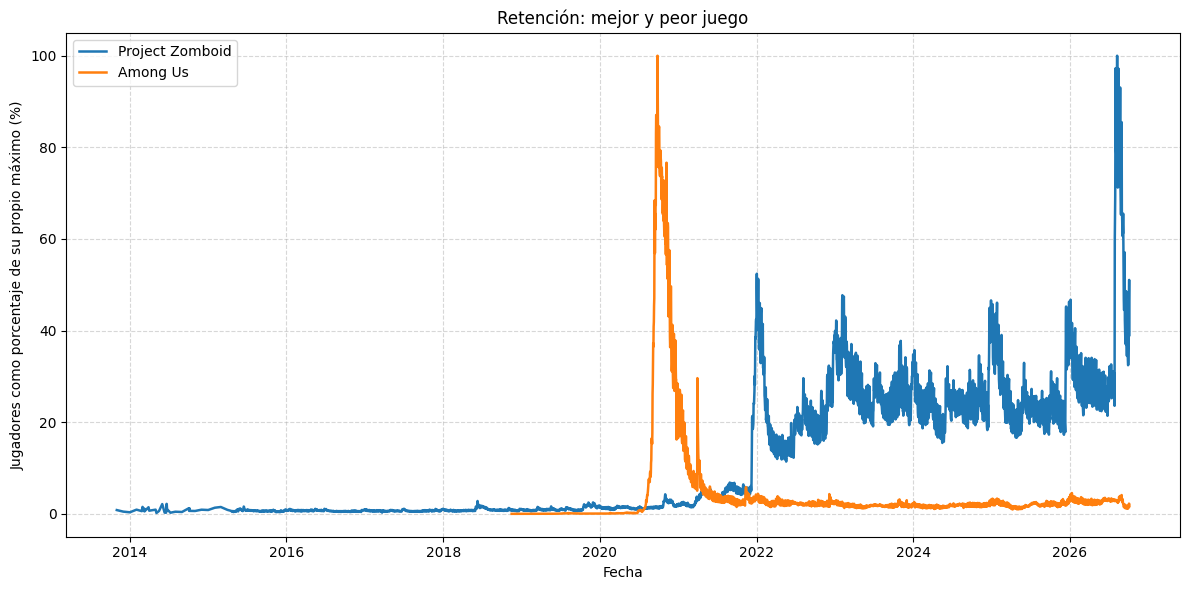

In [16]:
# Celda autosuficiente: recalcula en lugar de reutilizar variables ajenas.
plot_comparacion, plot_historiales = calcular_retencion(diario_juego)

retencion_mejor_juego = plot_comparacion.iloc[0]["Juego"]
retencion_peor_juego = plot_comparacion.iloc[-1]["Juego"]

plt.figure(figsize=(12, 6))

for juego in [retencion_mejor_juego, retencion_peor_juego]:
    historial, pico = plot_historiales[juego]
    porcentaje_del_pico = (historial["Players"] / pico * 100).round(2)

    plt.plot(
        historial["Fecha"],
        porcentaje_del_pico,
        label=juego,
        linewidth=1.8,
    )

ax = plt.gca()
configurar(ax, "Retención: mejor y peor juego", "Fecha",
           "Jugadores como porcentaje de su propio máximo (%)")
ax.legend()
plt.tight_layout()
plt.show()

### ¿Cual es el juego mas estable?

In [17]:
# Un promedio por juego y día (reutiliza el marco canonico diario).
estabilidad_base = diario_juego

# Variación de jugadores a lo largo de los días
estabilidad_tabla = (
    estabilidad_base.groupby("Game")["Players"]
    .agg(
        **{
            "Promedio diario": "mean",
            "Desviación estándar": "std"
        }
    )
    .reset_index()
)

# Porcentaje de variación respecto al promedio.
# Cuanto menor sea, más estable es el juego en relación con su tamaño.
estabilidad_tabla["Variación relativa (%)"] = (
    estabilidad_tabla["Desviación estándar"]
    / estabilidad_tabla["Promedio diario"]
    * 100
)

estabilidad_tabla = (
    estabilidad_tabla.dropna(subset=["Variación relativa (%)"])
    .sort_values("Variación relativa (%)")
    .reset_index(drop=True)
)

if estabilidad_tabla.empty:
    print("No hay datos suficientes para comparar la estabilidad.")
else:
    juego_mas_estable = estabilidad_tabla.iloc[0]

    print(
        f"El juego más estable es {juego_mas_estable['Game']}, "
        f"con una variación relativa del "
        f"{juego_mas_estable['Variación relativa (%)']:.2f} %."
    )

    tabla(estabilidad_tabla, {
        "Promedio diario": "{:,.2f}",
        "Desviación estándar": "{:,.2f}",
        "Variación relativa (%)": "{:.2f} %",
    })


El juego más estable es Dota 2, con una variación relativa del 35.71 %.


,Game,Promedio diario,Desviación estándar,Variación relativa (%)
0,Dota 2,"644,359.31","230,129.29",35.71 %
1,Team Fortress 2,"66,126.45","26,156.19",39.55 %
2,Rust,"79,591.28","48,520.33",60.96 %
3,Counter-Strike 2,"755,362.79","470,759.31",62.32 %
4,PUBG,"706,335.26","534,671.37",75.70 %
5,Terraria,"30,641.73","23,866.02",77.89 %
6,Stardew Valley,"43,713.68","38,741.98",88.63 %
7,Hollow Knight,"7,150.23","7,811.00",109.24 %
8,Project Zomboid,"14,551.08","17,507.45",120.32 %
9,Among Us,"19,586.41","51,577.24",263.33 %


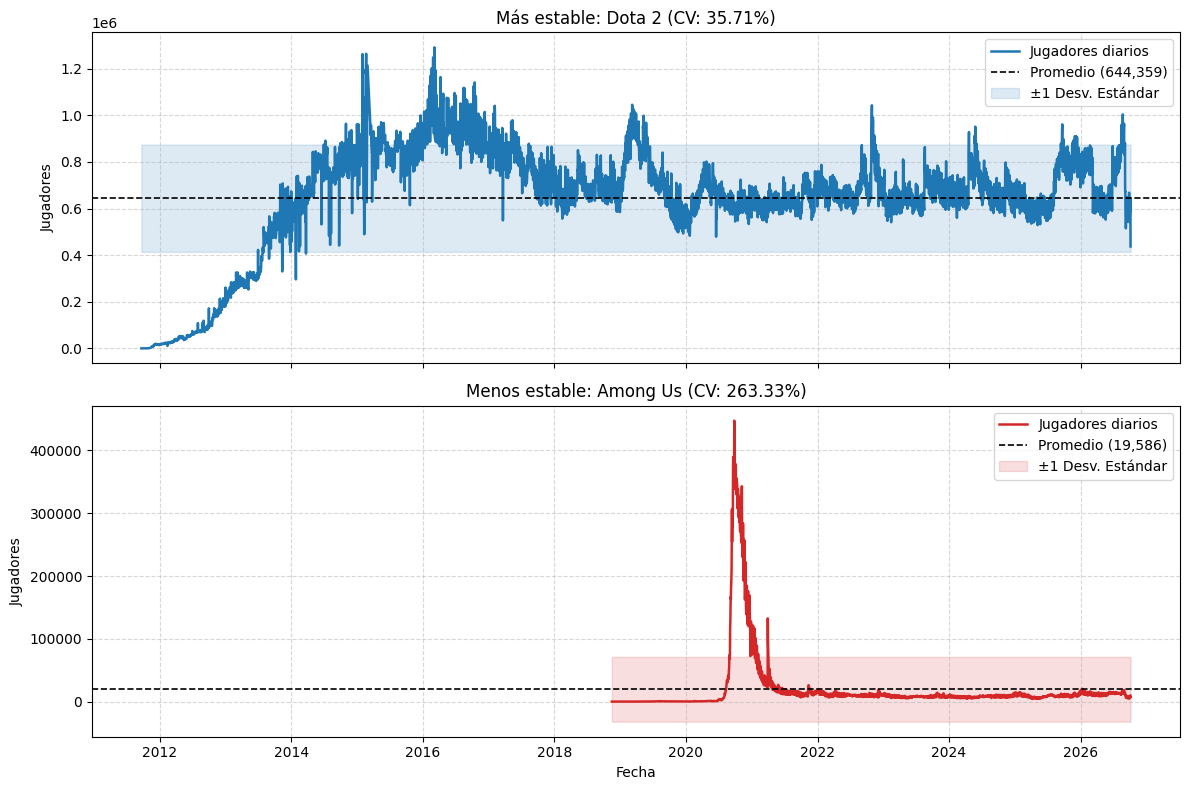

In [18]:
# Celda autosuficiente: recalcula en lugar de reutilizar variables ajenas.
est_plot_tabla = (
    diario_juego.groupby("Game")["Players"]
    .agg(
        **{
            "Promedio diario": "mean",
            "Desviación estándar": "std"
        }
    )
    .reset_index()
)

est_plot_tabla["Variación relativa (%)"] = (
    est_plot_tabla["Desviación estándar"]
    / est_plot_tabla["Promedio diario"]
    * 100
)

est_plot_tabla = (
    est_plot_tabla.dropna(subset=["Variación relativa (%)"])
    .sort_values("Variación relativa (%)")
    .reset_index(drop=True)
)

est_mejor_row = est_plot_tabla.iloc[0]
est_peor_row = est_plot_tabla.iloc[-1]

casos = [
    {
        "juego": est_mejor_row["Game"],
        "subtitulo": f"Más estable: {est_mejor_row['Game']} (CV: {est_mejor_row['Variación relativa (%)']:.2f}%)",
        "color": "#1f77b4"
    },
    {
        "juego": est_peor_row["Game"],
        "subtitulo": f"Menos estable: {est_peor_row['Game']} (CV: {est_peor_row['Variación relativa (%)']:.2f}%)",
        "color": "#d62728"
    }
]

fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(12, 8), sharex=True)

for ax, caso in zip(axes, casos):
    historial = (
        diario_juego.loc[diario_juego["Game"] == caso["juego"]]
        .sort_values("Fecha")
    )
    media = historial["Players"].mean()
    std = historial["Players"].std()

    # Serie diaria de jugadores reales
    ax.plot(
        historial["Fecha"],
        historial["Players"],
        color=caso["color"],
        linewidth=1.8,
        label="Jugadores diarios"
    )

    # Línea de promedio global y franja de dispersión (+/- 1 desv. estándar)
    ax.axhline(
        media,
        color="black",
        linestyle="--",
        linewidth=1.2,
        label=f"Promedio ({media:,.0f})"
    )
    ax.fill_between(
        historial["Fecha"],
        media - std,
        media + std,
        color=caso["color"],
        alpha=0.15,
        label="±1 Desv. Estándar"
    )

    configurar(ax, caso["subtitulo"], "Fecha" if ax == axes[-1] else "", "Jugadores")
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

### ¿Cual ha sido el año con mayor numero de jugadores?

El año con mayor promedio diario de jugadores fue 2025, con 3,286,738 jugadores.


,Año,Promedio diario de jugadores
0,2025,"3,286,738"
1,2026,"3,166,298"
2,2024,"3,072,523"
3,2018,"2,945,440"
4,2023,"2,685,585"
5,2017,"2,364,805"
6,2022,"2,350,769"
7,2020,"2,345,798"
8,2021,"2,242,377"
9,2019,"2,235,911"


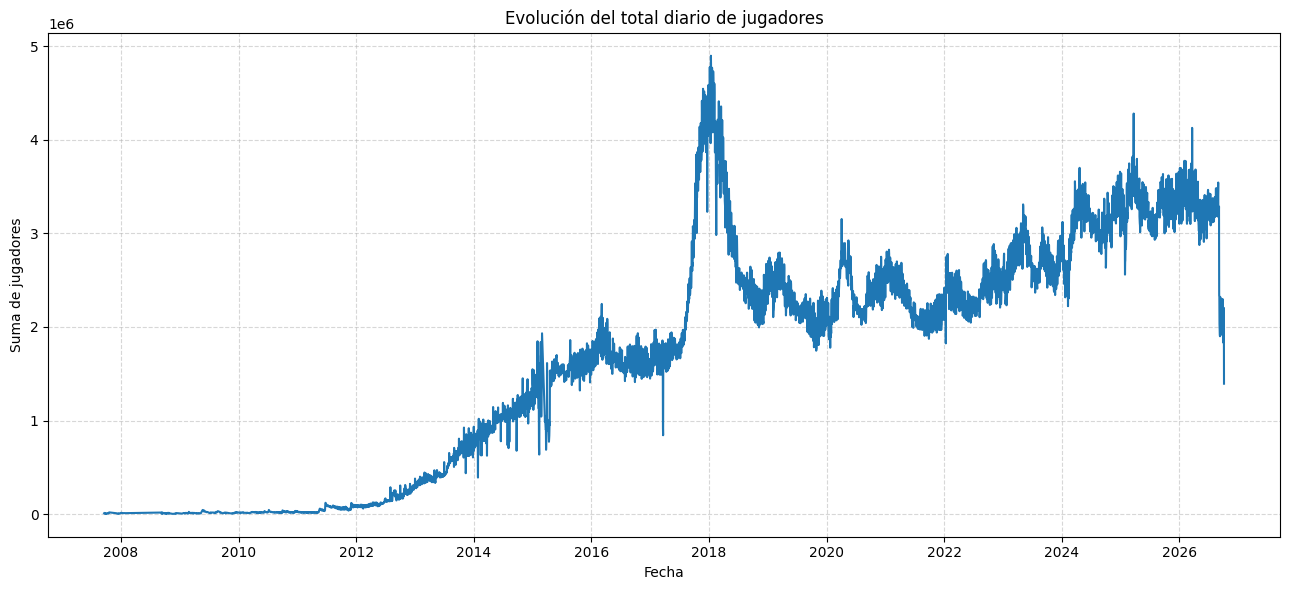

In [19]:
# Promedio diario por juego para que la frecuencia de medición no distorsione el resultado
anual_total = (
    diario_juego.groupby("Fecha")["Players"]
    .sum()
    .reset_index(name="Total de jugadores")
)
anual_total["Año"] = anual_total["Fecha"].dt.year

# Promedio del total diario para cada año
anual_jugadores = (
    anual_total.groupby("Año")["Total de jugadores"]
    .mean()
    .sort_values(ascending=False)
    .rename("Promedio diario de jugadores")
    .reset_index()
)

if anual_jugadores.empty:
    print("No hay datos suficientes para analizar los años.")
else:
    mejor_anio = anual_jugadores.iloc[0]

    print(
        f"El año con mayor promedio diario de jugadores fue "
        f"{int(mejor_anio['Año'])}, con "
        f"{mejor_anio['Promedio diario de jugadores']:,.0f} jugadores."
    )

    tabla(anual_jugadores, {"Promedio diario de jugadores": "{:,.0f}"})

    plt.figure(figsize=(13, 6))
    plt.plot(
        anual_total["Fecha"],
        anual_total["Total de jugadores"],
        linewidth=1.5,
    )
    ax = plt.gca()
    configurar(ax, "Evolución del total diario de jugadores",
               "Fecha", "Suma de jugadores")
    plt.tight_layout()
    plt.show()

- Hay que tener en cuenta que el año 2026 todavia no ha finalizado por lo que esos datos estan incompletos
- El pico al comienzo de 2018 se debe al pico de PUBG

### ¿Son los juegos mas populares actualmente mas antiguos o nuevos?

Popularidad calculada del 06/09/2026 al 05/10/2026.
Los tres juegos más populares son: Counter-Strike 2, Dota 2, PUBG.
Tienen una media de 13.19 años de historial, frente a 12.68 años del resto.
Los más populares tienen, en promedio, un historial más antiguo.


,Game,Promedio actual de jugadores,Días con datos recientes,Primer registro,Años de historial
0,Counter-Strike 2,831944,30,30/11/2011,14.85
1,Dota 2,587620,30,22/09/2011,15.04
2,PUBG,326319,30,01/02/2017,9.67
3,Rust,85976,30,01/12/2013,12.84
4,Team Fortress 2,59741,30,19/09/2007,19.04
5,Project Zomboid,53565,30,01/11/2013,12.93
6,Stardew Valley,50664,30,01/12/2015,10.84
7,Terraria,36254,30,15/05/2011,15.39
8,Among Us,7061,30,16/11/2018,7.89
9,Hollow Knight,6692,30,01/12/2016,9.84


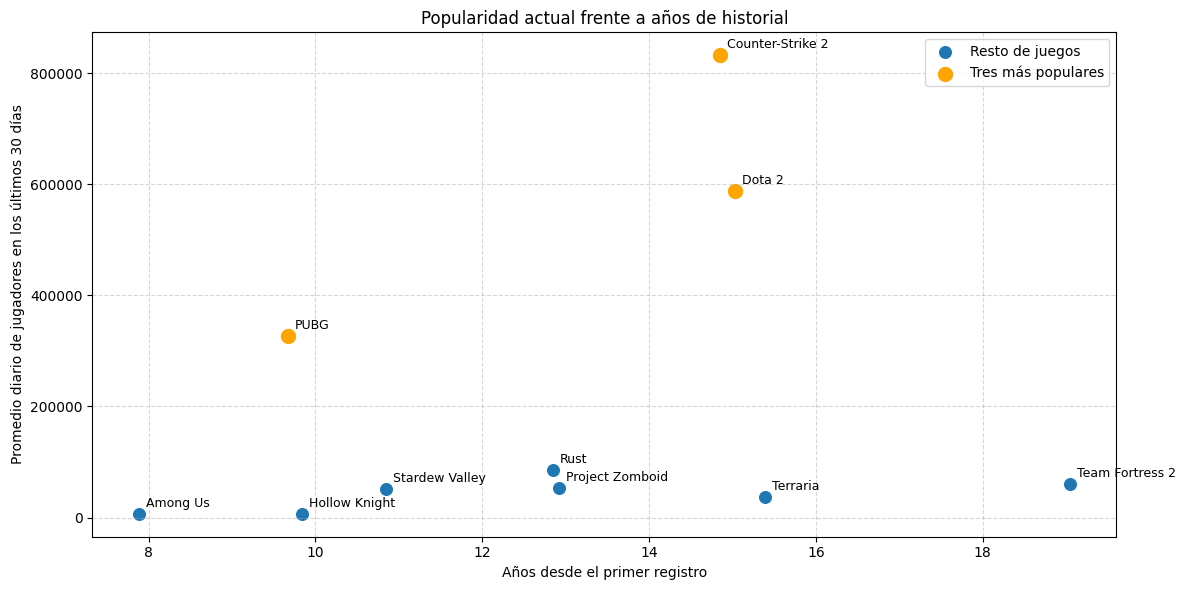

In [20]:
pop_fecha_final = diario_juego["Fecha"].max()
pop_fecha_inicio = pop_fecha_final - pd.Timedelta(days=29)

pop_primer_registro = df.groupby("Game")["Fecha"].min()

pop_recientes = diario_juego[
    diario_juego["Fecha"].between(pop_fecha_inicio, pop_fecha_final)
]

pop_comparacion = (
    pop_recientes.groupby("Game")["Players"]
    .agg(
        **{
            "Promedio actual de jugadores": "mean",
            "Días con datos recientes": "count"
        }
    )
    .join(pop_primer_registro.rename("Primer registro"))
    .reset_index()
)

pop_comparacion["Años de historial"] = (
    (pop_fecha_final - pop_comparacion["Primer registro"]).dt.days / 365.25
)

pop_comparacion = (
    pop_comparacion.dropna(subset=["Promedio actual de jugadores"])
    .sort_values("Promedio actual de jugadores", ascending=False)
    .reset_index(drop=True)
)

if len(pop_comparacion) < 4:
    print("Se necesitan al menos cuatro juegos para comparar los tres más populares con el resto.")
else:
    top_tres = pop_comparacion.head(3)
    resto = pop_comparacion.iloc[3:]

    historial_top = top_tres["Años de historial"].mean()
    historial_resto = resto["Años de historial"].mean()

    print(
        f"Popularidad calculada del {pop_fecha_inicio:%d/%m/%Y} "
        f"al {pop_fecha_final:%d/%m/%Y}."
    )
    print(
        f"Los tres juegos más populares son: "
        f"{', '.join(top_tres['Game'])}."
    )
    print(
        f"Tienen una media de {historial_top:.2f} años de historial, "
        f"frente a {historial_resto:.2f} años del resto."
    )

    if historial_top > historial_resto:
        print("Los más populares tienen, en promedio, un historial más antiguo.")
    elif historial_top < historial_resto:
        print("Los más populares tienen, en promedio, un historial más reciente.")
    else:
        print("Ambos grupos tienen la misma antigüedad media del historial.")

    tabla(pop_comparacion, {
        "Promedio actual de jugadores": "{:.0f}",
        "Primer registro": lambda fecha: fecha.strftime("%d/%m/%Y"),
        "Años de historial": "{:.2f}",
    })

    plt.figure(figsize=(12, 6))
    plt.scatter(
        resto["Años de historial"],
        resto["Promedio actual de jugadores"],
        label="Resto de juegos",
        s=70,
    )
    plt.scatter(
        top_tres["Años de historial"],
        top_tres["Promedio actual de jugadores"],
        color="orange",
        label="Tres más populares",
        s=100,
    )

    for _, fila in pop_comparacion.iterrows():
        plt.annotate(
            fila["Game"],
            (fila["Años de historial"], fila["Promedio actual de jugadores"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=9,
        )

    ax = plt.gca()
    configurar(ax, "Popularidad actual frente a años de historial",
               "Años desde el primer registro",
               "Promedio diario de jugadores en los últimos 30 días")
    ax.legend()
    plt.tight_layout()
    plt.show()

### ¿Que juegos han crecido en jugadores en el ultimo año?

Período actual: 06/09/2026 – 05/10/2026
Período anterior: 06/09/2025 – 05/10/2025
Han crecido: Project Zomboid, Terraria, Team Fortress 2.


,Game,Promedio actual,Días actuales con datos,Promedio hace un año,Días anteriores con datos,Cambio de jugadores,Cambio (%)
0,Project Zomboid,53565,30,26765,30,+26801,+100.13 %
1,Terraria,36254,30,29652,30,+6602,+22.26 %
2,Team Fortress 2,59741,30,57460,30,+2281,+3.97 %
3,Among Us,7061,30,9598,30,-2537,-26.44 %
4,Dota 2,587620,30,831639,30,-244018,-29.34 %
5,Rust,85976,30,126455,30,-40479,-32.01 %
6,Counter-Strike 2,831944,30,1432659,30,-600715,-41.93 %
7,PUBG,326319,30,652678,30,-326359,-50.00 %
8,Stardew Valley,50664,30,102624,30,-51960,-50.63 %
9,Hollow Knight,6692,30,65325,30,-58633,-89.76 %


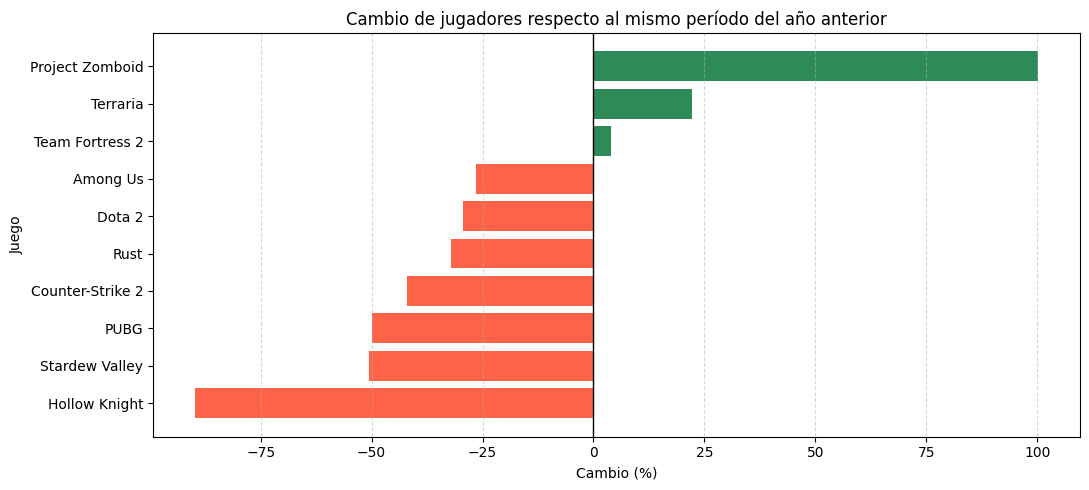

In [21]:
crec_fecha_final = diario_juego["Fecha"].max()
crec_inicio_actual = crec_fecha_final - pd.Timedelta(days=29)

crec_fin_anterior = crec_fecha_final - pd.DateOffset(years=1)
crec_inicio_anterior = crec_fin_anterior - pd.Timedelta(days=29)

crec_actual = diario_juego[
    diario_juego["Fecha"].between(crec_inicio_actual, crec_fecha_final)
]
crec_anterior = diario_juego[
    diario_juego["Fecha"].between(crec_inicio_anterior, crec_fin_anterior)
]

crec_resumen_actual = crec_actual.groupby("Game")["Players"].agg(
    **{
        "Promedio actual": "mean",
        "Días actuales con datos": "count"
    }
)

crec_resumen_anterior = crec_anterior.groupby("Game")["Players"].agg(
    **{
        "Promedio hace un año": "mean",
        "Días anteriores con datos": "count"
    }
)

crec_comparacion = (
    crec_resumen_actual.join(crec_resumen_anterior, how="outer")
    .reset_index()
)

# Solo compara períodos completos y bases positivas.
crec_comparables = (
    crec_comparacion["Días actuales con datos"].eq(30)
    & crec_comparacion["Días anteriores con datos"].eq(30)
    & crec_comparacion["Promedio hace un año"].gt(0)
)

crec_no_comparables = crec_comparacion.loc[~crec_comparables, "Game"]
crec_comparacion = crec_comparacion.loc[crec_comparables].copy()

crec_comparacion["Cambio de jugadores"] = (
    crec_comparacion["Promedio actual"]
    - crec_comparacion["Promedio hace un año"]
)
crec_comparacion["Cambio (%)"] = (
    crec_comparacion["Cambio de jugadores"]
    / crec_comparacion["Promedio hace un año"]
    * 100
)

crec_comparacion = crec_comparacion.sort_values(
    "Cambio (%)", ascending=False
).reset_index(drop=True)

print(
    f"Período actual: {crec_inicio_actual:%d/%m/%Y} "
    f"– {crec_fecha_final:%d/%m/%Y}"
)
print(
    f"Período anterior: {crec_inicio_anterior:%d/%m/%Y} "
    f"– {crec_fin_anterior:%d/%m/%Y}"
)

if not crec_no_comparables.empty:
    print(
        "No se pueden comparar por datos incompletos o promedio anterior "
        f"no positivo: {', '.join(crec_no_comparables)}."
    )

if crec_comparacion.empty:
    print("No hay juegos con datos suficientes para esta comparación.")
else:
    juegos_crecidos = crec_comparacion.loc[
        crec_comparacion["Cambio (%)"] > 0, "Game"
    ]

    if juegos_crecidos.empty:
        print("Ningún juego ha crecido en los períodos comparados.")
    else:
        print(f"Han crecido: {', '.join(juegos_crecidos)}.")

    tabla(crec_comparacion, {
        "Promedio actual": "{:.0f}",
        "Promedio hace un año": "{:.0f}",
        "Cambio de jugadores": "{:+.0f}",
        "Cambio (%)": "{:+.2f} %",
    })

    colores = [
        "seagreen" if cambio > 0 else "tomato"
        for cambio in crec_comparacion["Cambio (%)"]
    ]

    barras(
        crec_comparacion["Game"],
        crec_comparacion["Cambio (%)"],
        titulo="Cambio de jugadores respecto al mismo período del año anterior",
        xlabel="Cambio (%)",
        ylabel="Juego",
        horizontal=True,
        color=colores,
        linea_cero=True,
    )

### ¿Hay algun pico o tendencia que se repita a lo largo de varios juegos?

,Mes,Juegos que crecieron,Juegos comparables,Juegos
0,2020-04,10,10,"Among Us, Counter-Strike 2, Dota 2, Hollow Kni..."
1,2019-01,9,10,"Among Us, Counter-Strike 2, Dota 2, Hollow Kni..."
2,2024-12,9,10,"Among Us, Counter-Strike 2, Hollow Knight, PUB..."
3,2025-12,9,10,"Among Us, Counter-Strike 2, Dota 2, PUBG, Proj..."
4,2017-12,8,9,"Counter-Strike 2, Dota 2, Hollow Knight, PUBG,..."
5,2018-01,8,9,"Counter-Strike 2, Hollow Knight, PUBG, Project..."
6,2020-03,8,10,"Among Us, Counter-Strike 2, Dota 2, Project Zo..."
7,2020-11,8,10,"Counter-Strike 2, Dota 2, Hollow Knight, PUBG,..."
8,2021-01,8,10,"Counter-Strike 2, Dota 2, Hollow Knight, PUBG,..."
9,2021-11,8,10,"Among Us, Counter-Strike 2, Hollow Knight, Pro..."


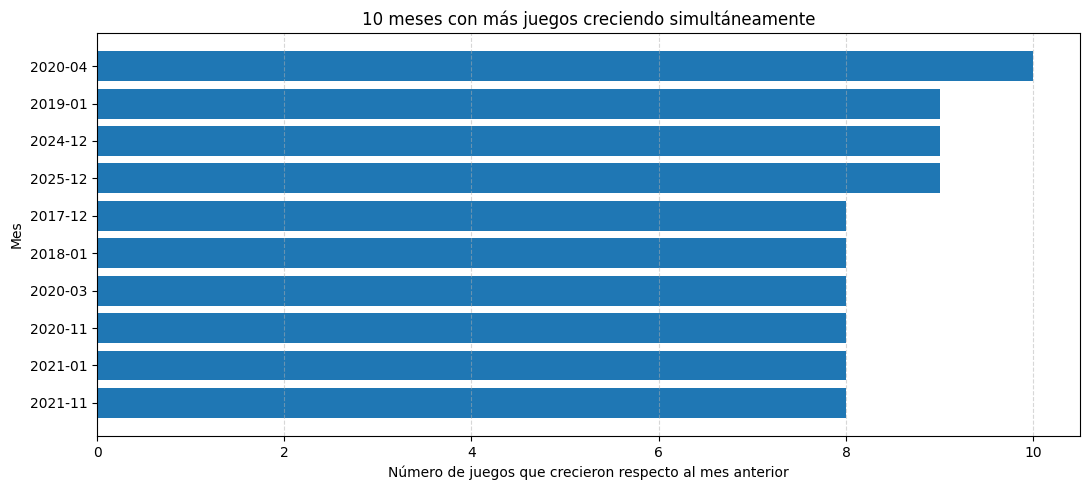

In [22]:
patron_mensuales = (
    diario_juego.assign(Mes=diario_juego["Fecha"].dt.to_period("M"))
    .groupby(["Game", "Mes"])["Players"]
    .agg(Promedio="mean", Dias_con_datos="count")
    .reset_index()
)

# Evita comparar meses con una cobertura muy incompleta.
patron_mensuales["Dias_del_mes"] = patron_mensuales["Mes"].dt.days_in_month
patron_mensuales.loc[
    patron_mensuales["Dias_con_datos"] / patron_mensuales["Dias_del_mes"] < 0.8,
    "Promedio"
] = float("nan")

patron_pivote = patron_mensuales.pivot(
    index="Mes", columns="Game", values="Promedio"
).sort_index()

patron_calendario = pd.period_range(
    patron_pivote.index.min(), patron_pivote.index.max(), freq="M"
)
patron_pivote = patron_pivote.reindex(patron_calendario)

patron_comparables = patron_pivote.notna() & patron_pivote.shift(1).notna()
patron_crecen = patron_pivote.gt(patron_pivote.shift(1)) & patron_comparables

patron_resumen = pd.DataFrame({
    "Juegos que crecieron": patron_crecen.sum(axis=1),
    "Juegos comparables": patron_comparables.sum(axis=1),
})

patron_resumen = patron_resumen[patron_resumen["Juegos que crecieron"] > 0].copy()
patron_resumen["Juegos"] = [
    ", ".join(patron_crecen.columns[patron_crecen.loc[mes]])
    for mes in patron_resumen.index
]

# En caso de empate, aparece primero el mes más antiguo.
patron_top10 = (
    patron_resumen.sort_values("Juegos que crecieron", ascending=False, kind="stable")
    .head(10)
    .reset_index(names="Mes")
)
patron_top10["Mes"] = patron_top10["Mes"].astype(str)

display(patron_top10)

barras(
    patron_top10["Mes"],
    patron_top10["Juegos que crecieron"],
    titulo="10 meses con más juegos creciendo simultáneamente",
    xlabel="Número de juegos que crecieron respecto al mes anterior",
    ylabel="Mes",
    horizontal=True,
)

### ¿Cual es la tendencia general respecto a la popularidad de los videojuegos?

En 2023–2025, el juego típico varió un +5.37 % anual: la tendencia reciente es creciente.


,Año,Juegos comparados,Juegos que crecieron,Crecimiento mediano (%),% de juegos que crecieron
0,2011,1,1,+86.00 %,100.00 %
1,2012,1,1,+50.36 %,100.00 %
2,2013,3,3,+78.32 %,100.00 %
3,2014,4,3,+51.16 %,75.00 %
4,2015,5,4,+17.38 %,80.00 %
5,2016,5,3,+6.12 %,60.00 %
6,2017,7,3,-0.76 %,42.86 %
7,2018,8,4,+4.35 %,50.00 %
8,2019,9,7,+19.70 %,77.78 %
9,2020,10,8,+47.05 %,80.00 %


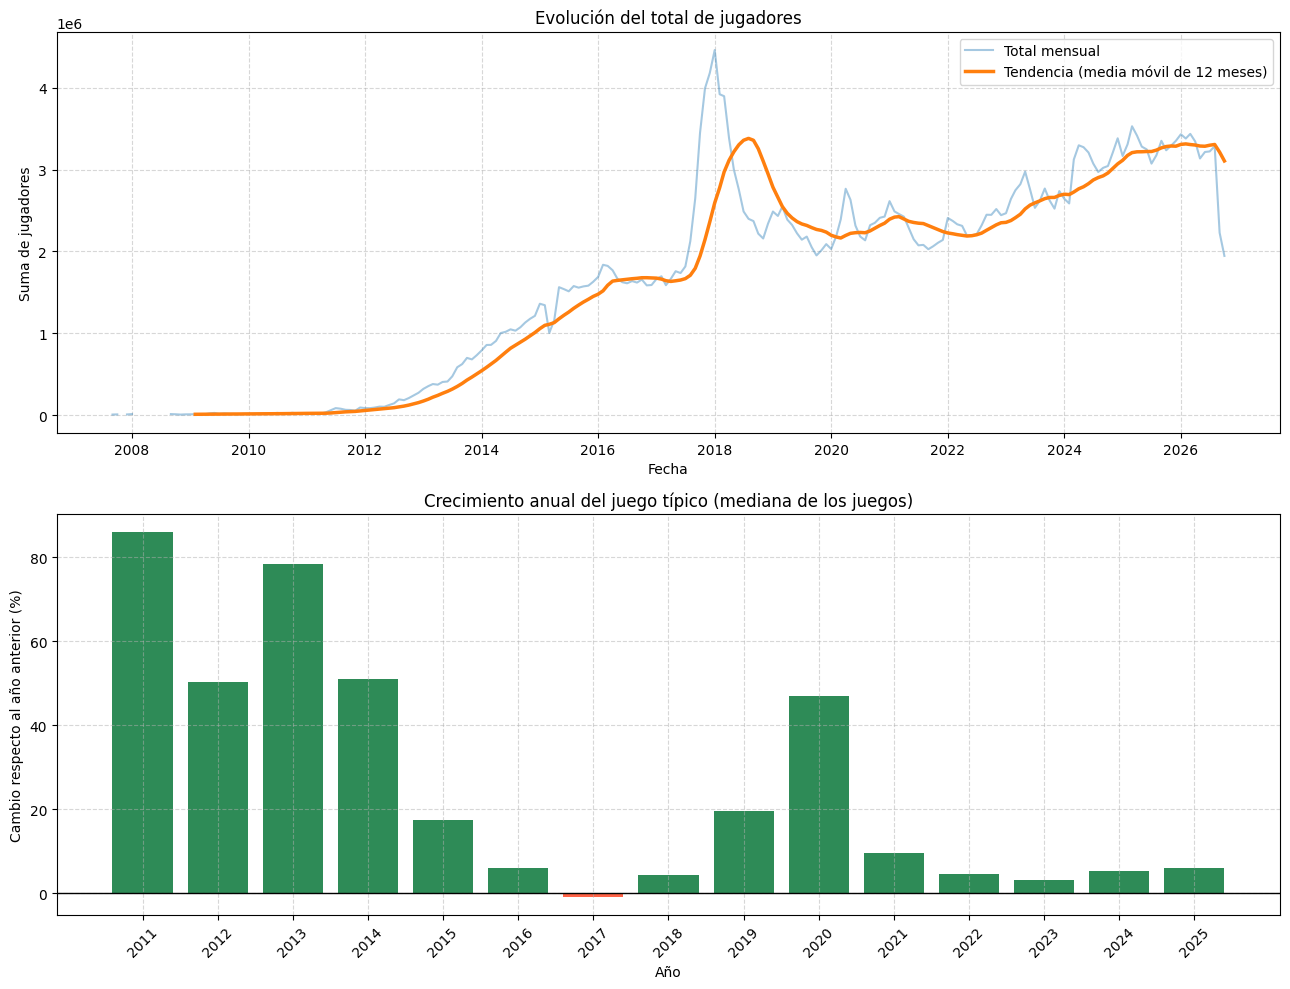

In [23]:
# 1. Evolución del total de jugadores
tend_total_mensual = (
    diario_juego.groupby("Fecha")["Players"].sum()
    .resample("MS")
    .mean()
)
tend_media_12 = tend_total_mensual.rolling(12, min_periods=6).mean()

# 2. Crecimiento anual de cada juego respecto a sí mismo
tend_diarios = diario_juego.assign(Año=diario_juego["Fecha"].dt.year)
tend_anuales = (
    tend_diarios.groupby(["Game", "Año"])["Players"]
    .agg(Promedio="mean", Dias_con_datos="count")
    .reset_index()
)

# Solo se usan años con al menos 300 días de datos para comparar años completos.
tend_anuales = tend_anuales[tend_anuales["Dias_con_datos"] >= 300]

tend_pivote = tend_anuales.pivot(index="Año", columns="Game", values="Promedio")
tend_pivote = tend_pivote.reindex(
    range(tend_pivote.index.min(), tend_pivote.index.max() + 1)
)
tend_anterior = tend_pivote.shift(1)
tend_cambios = ((tend_pivote / tend_anterior - 1) * 100).where(tend_anterior > 0)

tend_resumen = pd.DataFrame({
    "Juegos comparados": tend_cambios.count(axis=1),
    "Juegos que crecieron": (tend_cambios > 0).sum(axis=1),
    "Crecimiento mediano (%)": tend_cambios.median(axis=1),
})
tend_resumen = tend_resumen[tend_resumen["Juegos comparados"] > 0]
tend_resumen["% de juegos que crecieron"] = (
    tend_resumen["Juegos que crecieron"]
    / tend_resumen["Juegos comparados"]
    * 100
)
tend_resumen = tend_resumen.reset_index(names="Año")

# Conclusión basada en los últimos 3 años comparables
tend_ultimos = tend_resumen.tail(3)

if tend_ultimos.empty:
    print("No hay suficientes años completos para comparar.")
else:
    tend_mediana = tend_ultimos["Crecimiento mediano (%)"].median()
    tend_anios = f"{tend_ultimos['Año'].min()}–{tend_ultimos['Año'].max()}"

    if tend_mediana > 0:
        tendencia = "creciente"
    elif tend_mediana < 0:
        tendencia = "decreciente"
    else:
        tendencia = "estable"

    print(
        f"En {tend_anios}, el juego típico varió un {tend_mediana:+.2f} % "
        f"anual: la tendencia reciente es {tendencia}."
    )

tabla(tend_resumen, {
    "Crecimiento mediano (%)": "{:+.2f} %",
    "% de juegos que crecieron": "{:.2f} %",
})

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 10))

ax1.plot(tend_total_mensual.index, tend_total_mensual.values, alpha=0.4, label="Total mensual")
ax1.plot(
    tend_media_12.index,
    tend_media_12.values,
    linewidth=2.5,
    label="Tendencia (media móvil de 12 meses)",
)
configurar(ax1, "Evolución del total de jugadores", "Fecha", "Suma de jugadores")
ax1.legend()

tend_colores = [
    "seagreen" if valor > 0 else "tomato"
    for valor in tend_resumen["Crecimiento mediano (%)"]
]
ax2.bar(
    tend_resumen["Año"].astype(str),
    tend_resumen["Crecimiento mediano (%)"],
    color=tend_colores,
)
ax2.axhline(0, color="black", linewidth=1)
configurar(ax2, "Crecimiento anual del juego típico (mediana de los juegos)",
           "Año", "Cambio respecto al año anterior (%)", rotacion_x=45)

plt.tight_layout()
plt.show()

### ¿Existe correlacion entre los jugadores de Steam y los espectadores de Twitch?

Se cruza el promedio mensual de jugadores simultáneos de Steam con los espectadores medios mensuales de Twitch, mes a mes y juego a juego. El coeficiente de correlación de Pearson (r) va de -1 a 1: cerca de 1 indica que ambas señales suben y bajan juntas, cerca de 0 indica que no hay relación lineal apreciable.

In [24]:
MIN_MESES_CORRELACION = 2

correlacion_partes = []
correlacion_excluidos = []

for juego, historial in mensual_juego.groupby("Game"):
    pares = historial.dropna(subset=["Players", "AverageViewers"])
    if len(pares) < MIN_MESES_CORRELACION:
        correlacion_excluidos.append(juego)
        continue
    correlacion_partes.append(
        {
            "Juego": juego,
            "Meses comparados": len(pares),
            "Correlación (r)": pares["Players"].corr(pares["AverageViewers"]),
        }
    )

if correlacion_excluidos:
    print(
        "Sin meses suficientes para correlacionar: "
        + ", ".join(correlacion_excluidos)
    )

correlacion_tabla = pd.DataFrame(correlacion_partes)

if correlacion_tabla.empty:
    print("No hay juegos con datos suficientes para correlacionar.")
else:
    correlacion_tabla["Fuerza"] = correlacion_tabla["Correlación (r)"].abs()
    correlacion_tabla = (
        correlacion_tabla.sort_values("Fuerza", ascending=False)
        .drop(columns="Fuerza")
        .reset_index(drop=True)
    )

    mas_fuerte = correlacion_tabla.iloc[0]
    mas_debil = correlacion_tabla.iloc[-1]

    print(
        f"{mas_fuerte['Juego']} es el que más relación muestra "
        f"(r = {mas_fuerte['Correlación (r)']:+.3f})."
    )
    print(
        f"{mas_debil['Juego']} es el que menos relación muestra "
        f"(r = {mas_debil['Correlación (r)']:+.3f})."
    )

    tabla(correlacion_tabla, {"Correlación (r)": "{:+.3f}"})

Among Us es el que más relación muestra (r = +0.965).
Dota 2 es el que menos relación muestra (r = +0.031).


,Juego,Meses comparados,Correlación (r)
0,Among Us,95,+0.965
1,Terraria,134,+0.817
2,Project Zomboid,134,+0.756
3,Hollow Knight,118,+0.719
4,PUBG,116,+0.610
5,Counter-Strike 2,134,+0.578
6,Rust,134,+0.532
7,Team Fortress 2,134,+0.448
8,Stardew Valley,130,+0.392
9,Dota 2,134,+0.031


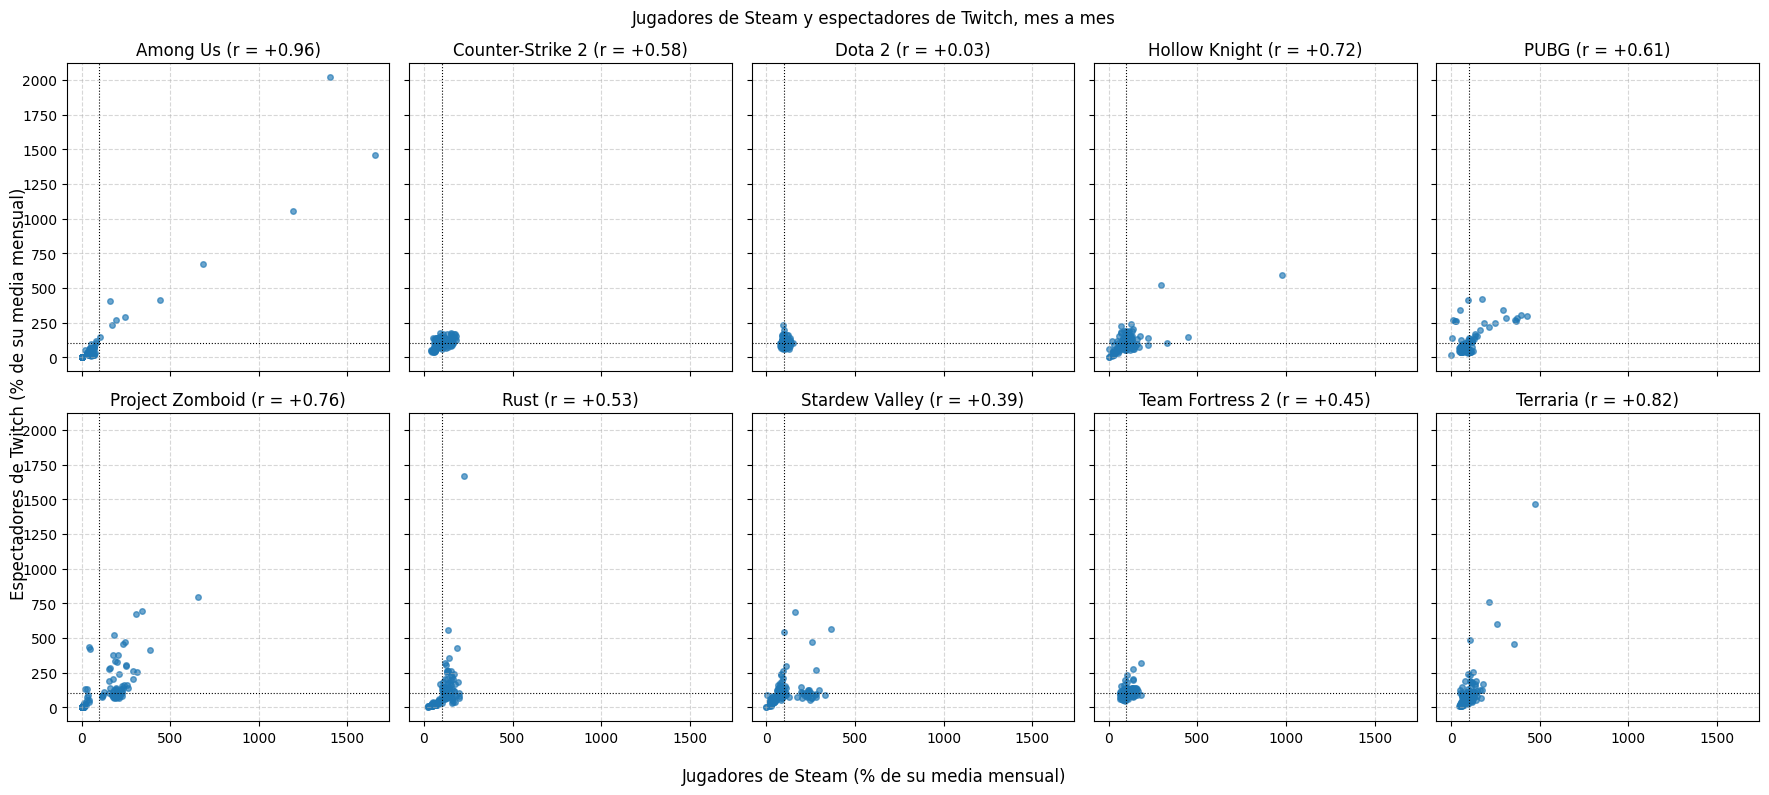

In [25]:
# Celda autosuficiente: recalcula en lugar de reutilizar variables ajenas.
pares_por_juego = []
for juego, historial in mensual_juego.groupby("Game"):
    pares = historial.dropna(subset=["Players", "AverageViewers"]).sort_values("Mes")
    if len(pares) < 2:
        continue
    pares_por_juego.append(
        (
            juego,
            pares["Players"] / pares["Players"].mean() * 100,
            pares["AverageViewers"] / pares["AverageViewers"].mean() * 100,
            pares["Players"].corr(pares["AverageViewers"]),
        )
    )

fig, axes = plt.subplots(2, 5, figsize=(18, 8), sharex=True, sharey=True)

for eje, (juego, steam_normalizado, twitch_normalizado, r) in zip(
    axes.flat, pares_por_juego
):
    eje.scatter(steam_normalizado, twitch_normalizado, s=16, alpha=0.65)
    eje.axhline(100, color="black", linewidth=0.8, linestyle=":")
    eje.axvline(100, color="black", linewidth=0.8, linestyle=":")
    configurar(eje, f"{juego} (r = {r:+.2f})", "", "")

for eje in axes.flat[len(pares_por_juego):]:
    eje.set_visible(False)

fig.suptitle("Jugadores de Steam y espectadores de Twitch, mes a mes")
fig.supxlabel("Jugadores de Steam (% de su media mensual)")
fig.supylabel("Espectadores de Twitch (% de su media mensual)")
plt.tight_layout()
plt.show()

### ¿Quien se mueve primero: Twitch o Steam?

Para cada juego se compara su serie mensual de jugadores con la de espectadores desplazada varios meses. Si la mejor correlación aparece cuando Twitch va por delante, el interés por ver el juego se adelanta a su instalación; si aparece con Steam por delante, ocurre lo contrario. El desfase se mueve entre -3 y +3 meses y solo se acepta una relación cuando la correlación supera un umbral de 0.3 en valor absoluto.

**Ejemplo trabajado: Among Us.** Su pico de audiencia llegó en septiembre de 2020, cuando promedió 204 634 espectadores. La siguiente celda calcula su curva de desfases para ver cuántos meses separan el pico de espectadores del pico de jugadores.

In [26]:
ejemplo_juego = "Among Us"
ejemplo_historial = mensual_juego[mensual_juego["Game"] == ejemplo_juego]
ejemplo_pares = (
    ejemplo_historial.dropna(subset=["Players", "AverageViewers"]).sort_values("Mes")
)

jugadores_ejemplo = ejemplo_pares["Players"].to_numpy()
espectadores_ejemplo = ejemplo_pares["AverageViewers"].to_numpy()

print(f"{ejemplo_juego}: {len(ejemplo_pares)} meses con ambas señales")
fila_pico = ejemplo_pares.loc[ejemplo_pares["AverageViewers"].idxmax()]
print(
    f"Pico de espectadores: {fila_pico['Mes']} "
    f"({fila_pico['AverageViewers']:,.0f} espectadores medios)"
)

for desfase in range(-3, 4):
    if desfase > 0:
        parte_steam, parte_twitch = (
            jugadores_ejemplo[desfase:],
            espectadores_ejemplo[:-desfase],
        )
    elif desfase < 0:
        parte_steam, parte_twitch = (
            jugadores_ejemplo[:desfase],
            espectadores_ejemplo[-desfase:],
        )
    else:
        parte_steam, parte_twitch = jugadores_ejemplo, espectadores_ejemplo
    r = float(np.corrcoef(parte_steam, parte_twitch)[0, 1])
    print(f"  desfase {desfase:+d} meses: r = {r:+.3f}")

ejemplo_clasificacion = clasificar_desfase(ejemplo_juego, ejemplo_historial)

if ejemplo_clasificacion is not None:
    print()
    print(
        f"Mejor desfase para {ejemplo_juego}: "
        f"{ejemplo_clasificacion['Desfase (meses)']:+d} meses "
        f"(r = {ejemplo_clasificacion['Correlación (r)']:+.3f}) -> "
        f"{ejemplo_clasificacion['Clasificación']}."
    )

Among Us: 95 meses con ambas señales
Pico de espectadores: 2020-09 (204,634 espectadores medios)
  desfase -3 meses: r = +0.247
  desfase -2 meses: r = +0.431
  desfase -1 meses: r = +0.682
  desfase +0 meses: r = +0.965
  desfase +1 meses: r = +0.894
  desfase +2 meses: r = +0.608
  desfase +3 meses: r = +0.338

Mejor desfase para Among Us: +0 meses (r = +0.965) -> Sincronizados.


In [27]:
UMBRAL_DESFASE = 0.3

clasificaciones = []
juegos_sin_desfase = []

for juego, historial in mensual_juego.groupby("Game"):
    resultado = clasificar_desfase(juego, historial, umbral=UMBRAL_DESFASE)
    if resultado is None:
        juegos_sin_desfase.append(juego)
    else:
        clasificaciones.append(resultado)

if juegos_sin_desfase:
    print(
        "Sin meses suficientes para calcular el desfase: "
        + ", ".join(juegos_sin_desfase)
    )

desfase_tabla = pd.DataFrame(clasificaciones)

if desfase_tabla.empty:
    print("No hay juegos con datos suficientes para comparar desfases.")
else:
    con_relacion = desfase_tabla["Clasificación"] != "Sin relación clara"
    en_el_borde = desfase_tabla["Desfase (meses)"].abs().eq(3) & con_relacion
    if en_el_borde.any():
        juegos_en_el_borde = desfase_tabla.loc[en_el_borde, "Juego"].tolist()
        verbo = "cae" if len(juegos_en_el_borde) == 1 else "caen"
        print(
            f"Aviso: el desfase de {', '.join(juegos_en_el_borde)} {verbo} en el "
            "borde de la ventana (±3 meses); conviene leerlo con cautela."
        )

    for clasificacion, cantidad in desfase_tabla["Clasificación"].value_counts().items():
        print(f"{clasificacion}: {cantidad} juego(s)")

    desfase_tabla = (
        desfase_tabla.assign(Fuerza=desfase_tabla["Correlación (r)"].abs())
        .sort_values("Fuerza", ascending=False)
        .drop(columns="Fuerza")
        .reset_index(drop=True)
    )

    tabla(
        desfase_tabla,
        {"Correlación (r)": "{:+.3f}", "Desfase (meses)": "{:+d}"},
    )

Aviso: el desfase de PUBG cae en el borde de la ventana (±3 meses); conviene leerlo con cautela.
Sincronizados: 8 juego(s)
Sin relación clara: 1 juego(s)
Twitch se adelanta: 1 juego(s)


,Juego,Desfase (meses),Correlación (r),Clasificación,Meses comparados
0,Among Us,+0,+0.965,Sincronizados,95
1,PUBG,+3,+0.824,Twitch se adelanta,116
2,Terraria,+0,+0.817,Sincronizados,134
3,Project Zomboid,+0,+0.756,Sincronizados,134
4,Hollow Knight,+0,+0.719,Sincronizados,118
5,Counter-Strike 2,+0,+0.578,Sincronizados,134
6,Rust,+0,+0.532,Sincronizados,134
7,Team Fortress 2,+0,+0.448,Sincronizados,134
8,Stardew Valley,+0,+0.392,Sincronizados,130
9,Dota 2,-3,-0.140,Sin relación clara,134


### ¿Los saltos de audiencia de Twitch se reflejan en Steam?

Para cada juego se busca el mes en el que su audiencia de Twitch creció más respecto al mes anterior y se compara con el cambio de jugadores de Steam en ese mismo mes y en los meses contiguos. Para que un porcentaje de cambio sea interpretable se exige que el mes anterior tenga al menos el 1 % del máximo histórico del juego: sin esa protección, un salto desde una audiencia casi nula produce porcentajes enormes y engañosos (por ejemplo, un cambio de 3 844 669 % en PUBG).

In [28]:
UMBRAL_BASE_RELATIVA = 0.01

momentos = []

for juego, historial in mensual_juego.groupby("Game"):
    serie = historial.sort_values("Mes").copy()
    espectadores_previos = serie["AverageViewers"].shift(1)
    jugadores_previos = serie["Players"].shift(1)

    serie["Cambio espectadores (%)"] = (
        (serie["AverageViewers"] - espectadores_previos) / espectadores_previos * 100
    )
    serie["Cambio jugadores (%)"] = (
        (serie["Players"] - jugadores_previos) / jugadores_previos * 100
    )

    # Porcentajes sobre bases casi nulas no son interpretables.
    base_espectadores = max(1, serie["AverageViewers"].max() * UMBRAL_BASE_RELATIVA)
    base_jugadores = max(1, serie["Players"].max() * UMBRAL_BASE_RELATIVA)
    serie.loc[
        espectadores_previos < base_espectadores, "Cambio espectadores (%)"
    ] = np.nan
    serie.loc[jugadores_previos < base_jugadores, "Cambio jugadores (%)"] = np.nan
    serie = serie.replace([np.inf, -np.inf], np.nan)

    validos = serie[serie["Cambio espectadores (%)"].notna()]
    if validos.empty:
        continue

    fila_salto = validos.loc[validos["Cambio espectadores (%)"].idxmax()]
    posicion = serie.index.get_loc(fila_salto.name)

    mejor_desfase = None
    mejor_cambio = None
    for desfase in (-1, 0, 1):
        vecino = posicion + desfase
        if vecino < 0 or vecino >= len(serie):
            continue
        cambio = serie.iloc[vecino]["Cambio jugadores (%)"]
        if pd.isna(cambio):
            continue
        if mejor_cambio is None or cambio > mejor_cambio:
            mejor_cambio = cambio
            mejor_desfase = desfase

    momentos.append(
        {
            "Juego": juego,
            "Mes del salto": str(fila_salto["Mes"]),
            "Salto Twitch (%)": fila_salto["Cambio espectadores (%)"],
            "Steam mismo mes (%)": fila_salto["Cambio jugadores (%)"],
            "Mejor Steam ±1 mes (%)": mejor_cambio,
            "Desfase Steam (meses)": mejor_desfase,
        }
    )

momento_tabla = pd.DataFrame(momentos)

if momento_tabla.empty:
    print("No hay juegos con datos suficientes para detectar saltos.")
else:
    con_reflejo = momento_tabla[
        momento_tabla["Mejor Steam ±1 mes (%)"].fillna(0) > 0
    ]
    sin_reflejo = momento_tabla[
        momento_tabla["Mejor Steam ±1 mes (%)"].fillna(0) <= 0
    ]

    print(
        f"{len(con_reflejo)} de {len(momento_tabla)} juegos tuvieron también "
        "un aumento de jugadores en Steam alrededor de su mayor salto en Twitch."
    )
    if not sin_reflejo.empty:
        print(
            "Sin reflejo claro en Steam: " + ", ".join(sin_reflejo["Juego"]) + "."
        )

    formato_mejor = lambda valor: (
        "—" if pd.isna(valor) else f"{valor:+.1f} %"
    )

    tabla(
        momento_tabla,
        {
            "Salto Twitch (%)": "{:+.1f} %",
            "Steam mismo mes (%)": formato_mejor,
            "Mejor Steam ±1 mes (%)": formato_mejor,
            "Desfase Steam (meses)": lambda valor: (
                "—" if pd.isna(valor) else f"{int(valor):+d}"
            ),
        },
    )

10 de 10 juegos tuvieron también un aumento de jugadores en Steam alrededor de su mayor salto en Twitch.


,Juego,Mes del salto,Salto Twitch (%),Steam mismo mes (%),Mejor Steam ±1 mes (%),Desfase Steam (meses)
0,Among Us,2020-08,+634.7 %,+767.3 %,+781.1 %,+1
1,Counter-Strike 2,2018-01,+273.7 %,+15.9 %,+15.9 %,+0
2,Dota 2,2021-10,+174.7 %,+13.7 %,+13.7 %,+0
3,Hollow Knight,2025-08,+527.4 %,+97.7 %,+229.3 %,+1
4,PUBG,2017-03,+980.4 %,—,+143.8 %,+1
5,Project Zomboid,2021-12,+967.5 %,+329.4 %,+329.4 %,+0
6,Rust,2021-01,+891.6 %,+139.8 %,+139.8 %,+0
7,Stardew Valley,2016-03,+522.0 %,+1601.3 %,+1601.3 %,+0
8,Team Fortress 2,2023-07,+298.3 %,+75.6 %,+75.6 %,+0
9,Terraria,2020-05,+2066.9 %,+181.7 %,+181.7 %,+0


### ¿Divergen las trayectorias de Steam y Twitch?

Se ajusta una recta a los últimos tres años de cada serie y se mide su pendiente como porcentaje de la media del propio juego y mes. Así se comparan direcciones —no tamaños— entre dos señales con escalas muy distintas. Un juego se marca como divergente cuando Steam y Twitch apuntan en sentidos opuestos.

In [29]:
VENTANA_ANIOS = 3
MIN_MESES_TENDENCIA = 24
UMBRAL_TENDENCIA = 0.05

ventana_fin = mensual_juego["Mes"].max()
ventana_inicio = ventana_fin - VENTANA_ANIOS * 12


def pendiente_relativa(historial, columna):
    """Pendiente mensual de una serie, como % de su propia media."""
    datos = historial[
        (historial["Mes"] >= ventana_inicio) & (historial["Mes"] <= ventana_fin)
    ].dropna(subset=[columna])
    if len(datos) < MIN_MESES_TENDENCIA:
        return None
    media = datos[columna].mean()
    if media == 0:
        return None
    pendiente = np.polyfit(np.arange(len(datos)), datos[columna].to_numpy(), 1)[0]
    return pendiente / media * 100


def direccion(pendiente):
    if pendiente is None:
        return "Sin datos"
    if pendiente > UMBRAL_TENDENCIA:
        return "Crece"
    if pendiente < -UMBRAL_TENDENCIA:
        return "Decrece"
    return "Estable"


trayectorias = []
for juego, historial in mensual_juego.groupby("Game"):
    pendiente_steam = pendiente_relativa(historial, "Players")
    pendiente_twitch = pendiente_relativa(historial, "AverageViewers")
    direccion_steam = direccion(pendiente_steam)
    direccion_twitch = direccion(pendiente_twitch)

    divergen = (
        direccion_steam in ("Crece", "Decrece")
        and direccion_twitch in ("Crece", "Decrece")
        and direccion_steam != direccion_twitch
    )

    trayectorias.append(
        {
            "Juego": juego,
            "Pendiente Steam (%/mes)": pendiente_steam,
            "Pendiente Twitch (%/mes)": pendiente_twitch,
            "Tendencia Steam": direccion_steam,
            "Tendencia Twitch": direccion_twitch,
            "Divergen": "Sí" if divergen else "No",
        }
    )

trayectoria_tabla = (
    pd.DataFrame(trayectorias)
    .sort_values(["Divergen", "Juego"], ascending=[False, True])
    .reset_index(drop=True)
)

divergentes = trayectoria_tabla.loc[
    trayectoria_tabla["Divergen"] == "Sí", "Juego"
].tolist()
sin_datos = trayectoria_tabla.loc[
    (trayectoria_tabla["Tendencia Steam"] == "Sin datos")
    | (trayectoria_tabla["Tendencia Twitch"] == "Sin datos"),
    "Juego",
].tolist()

print(f"Ventana analizada: {ventana_inicio} a {ventana_fin}.")
if sin_datos:
    print("Sin datos suficientes en la ventana: " + ", ".join(sin_datos) + ".")

if divergentes:
    print("Trayectorias divergentes: " + ", ".join(divergentes) + ".")
    if "Counter-Strike 2" in divergentes:
        print(
            "Nota: la serie de Twitch de Counter-Strike 2 arranca en la época de CS:GO, "
            "así que su tendencia describe la franquicia, no solo a CS2."
        )
else:
    print("Ningún juego muestra trayectorias divergentes.")

formato_pendiente = lambda valor: "—" if pd.isna(valor) else f"{valor:+.2f}"

tabla(
    trayectoria_tabla,
    {
        "Pendiente Steam (%/mes)": formato_pendiente,
        "Pendiente Twitch (%/mes)": formato_pendiente,
    },
)

Ventana analizada: 2023-10 a 2026-10.
Trayectorias divergentes: Among Us, Dota 2, PUBG, Rust, Stardew Valley.


,Juego,Pendiente Steam (%/mes),Pendiente Twitch (%/mes),Tendencia Steam,Tendencia Twitch,Divergen
0,Among Us,+1.33,-1.41,Crece,Decrece,Sí
1,Dota 2,+0.15,-0.68,Crece,Decrece,Sí
2,PUBG,+0.39,-1.35,Crece,Decrece,Sí
3,Rust,+0.52,-0.64,Crece,Decrece,Sí
4,Stardew Valley,+0.65,-2.91,Crece,Decrece,Sí
5,Counter-Strike 2,+0.02,+0.50,Estable,Crece,No
6,Hollow Knight,+1.82,+0.72,Crece,Crece,No
7,Project Zomboid,+1.56,+1.63,Crece,Crece,No
8,Team Fortress 2,-1.70,-0.27,Decrece,Decrece,No
9,Terraria,+0.73,+0.74,Crece,Crece,No


### ¿Comparten los juegos un patron estacional entre plataformas?

Se promedian, para cada juego y cada mes del calendario, los jugadores de Steam y los espectadores de Twitch de todos los años disponibles. Después se normaliza cada serie respecto a su propia media (100 = mes medio) para poder compararlas. Si ambas plataformas suben y bajan en los mismos meses, el patrón es compartido; si no, el juego sigue un ciclo propio.

In [30]:
NOMBRES_MESES = [
    "Enero", "Febrero", "Marzo", "Abril", "Mayo", "Junio",
    "Julio", "Agosto", "Septiembre", "Octubre", "Noviembre", "Diciembre",
]

perfiles = []

for juego, historial in mensual_juego.groupby("Game"):
    mes_calendario = historial["Mes"].dt.month
    perfil_steam = (
        historial.groupby(mes_calendario)["Players"].mean().reindex(range(1, 13))
    )
    perfil_twitch = (
        historial.groupby(mes_calendario)["AverageViewers"].mean().reindex(range(1, 13))
    )

    if perfil_steam.notna().sum() < 12 or perfil_twitch.notna().sum() < 12:
        perfiles.append({"Juego": juego, "Perfil completo": "No"})
        continue

    steam_normalizado = perfil_steam / perfil_steam.mean() * 100
    twitch_normalizado = perfil_twitch / perfil_twitch.mean() * 100

    perfiles.append(
        {
            "Juego": juego,
            "Perfil completo": "Sí",
            "r entre perfiles": steam_normalizado.corr(twitch_normalizado),
            "Mes pico Steam": NOMBRES_MESES[int(steam_normalizado.idxmax()) - 1],
            "Mes pico Twitch": NOMBRES_MESES[int(twitch_normalizado.idxmax()) - 1],
            "Amplitud Steam (%)": steam_normalizado.max() - steam_normalizado.min(),
            "Amplitud Twitch (%)": twitch_normalizado.max() - twitch_normalizado.min(),
        }
    )

perfil_tabla = pd.DataFrame(perfiles)
completos = perfil_tabla[perfil_tabla["Perfil completo"] == "Sí"]

print(
    f"Perfiles completos (12 meses del calendario): "
    f"{len(completos)} de {len(perfil_tabla)} juegos."
)

if len(completos) < len(perfil_tabla):
    print(
        "Sin perfil completo: "
        + ", ".join(perfil_tabla.loc[perfil_tabla["Perfil completo"] == "No", "Juego"])
        + "."
    )

if not completos.empty:
    formato_amplitud = lambda valor: "—" if pd.isna(valor) else f"{valor:.1f} %"
    tabla(
        completos.sort_values("r entre perfiles", ascending=False).reset_index(drop=True),
        {
            "r entre perfiles": "{:+.3f}",
            "Amplitud Steam (%)": formato_amplitud,
            "Amplitud Twitch (%)": formato_amplitud,
        },
    )

Perfiles completos (12 meses del calendario): 10 de 10 juegos.


,Juego,Perfil completo,r entre perfiles,Mes pico Steam,Mes pico Twitch,Amplitud Steam (%),Amplitud Twitch (%)
0,Among Us,Sí,+0.959,Octubre,Septiembre,204.5 %,238.2 %
1,Project Zomboid,Sí,+0.894,Enero,Enero,52.7 %,129.2 %
2,Rust,Sí,+0.760,Enero,Enero,36.2 %,205.9 %
3,Terraria,Sí,+0.649,Julio,Mayo,41.8 %,158.7 %
4,Counter-Strike 2,Sí,+0.640,Abril,Marzo,21.2 %,39.8 %
5,Team Fortress 2,Sí,+0.612,Julio,Julio,22.7 %,42.1 %
6,Stardew Valley,Sí,+0.504,Julio,Marzo,47.0 %,114.6 %
7,Dota 2,Sí,+0.469,Agosto,Agosto,10.6 %,33.4 %
8,Hollow Knight,Sí,+0.331,Septiembre,Agosto,80.8 %,72.6 %
9,PUBG,Sí,-0.505,Enero,Julio,37.0 %,29.0 %


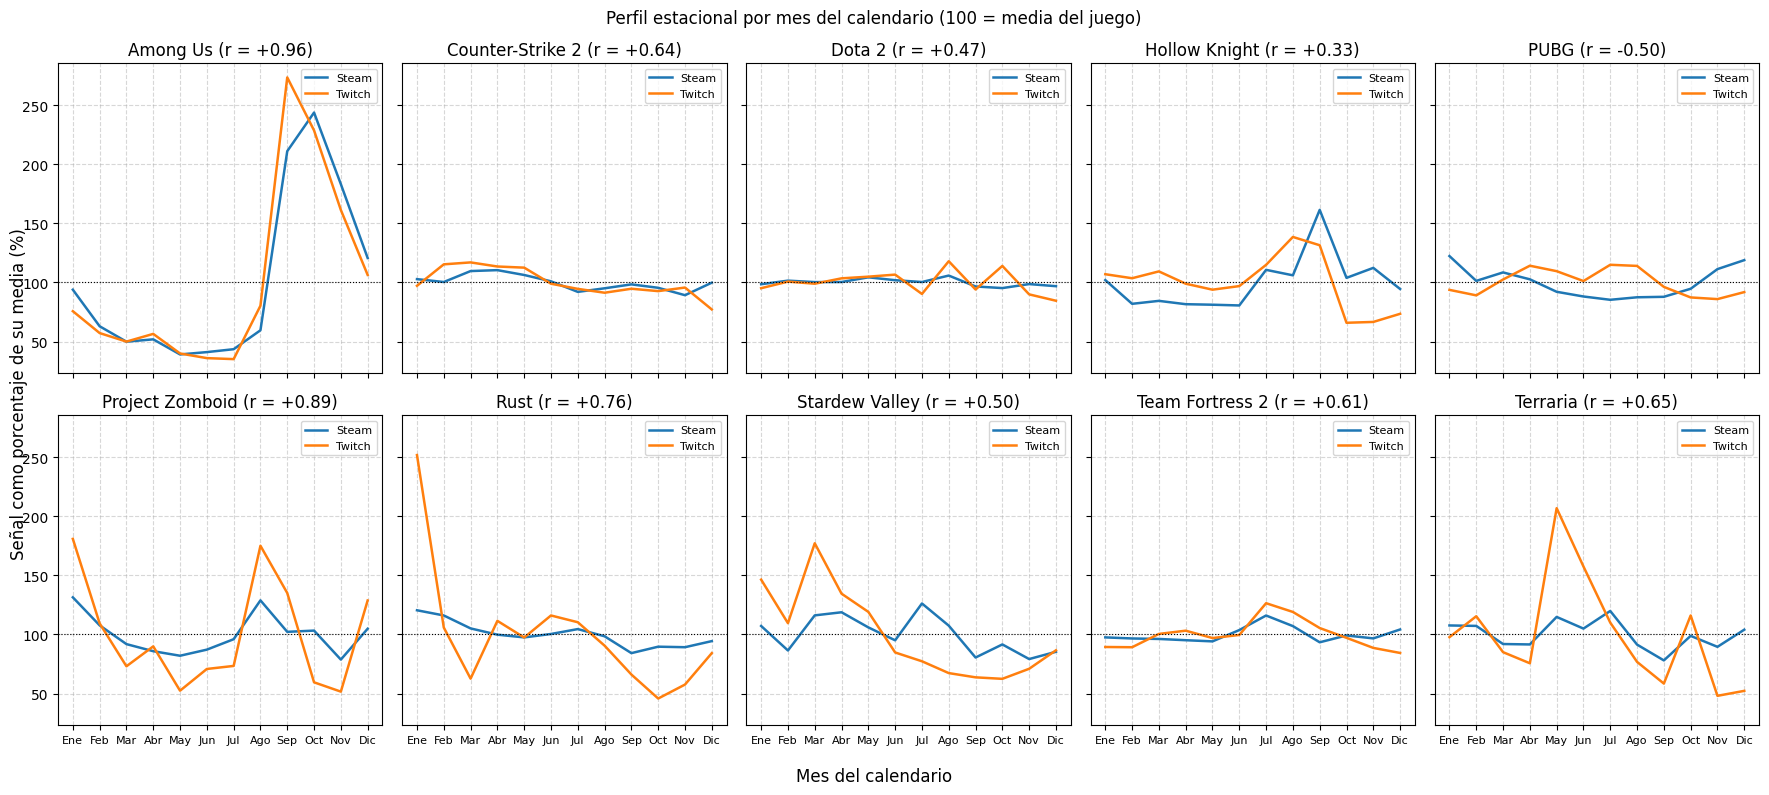

Patrón más compartido: Among Us (r = +0.96); Steam y Twitch se mueven en los mismos meses.
Patrón más propio: PUBG (r = -0.50); los picos de una plataforma no coinciden con la otra.


In [31]:
# Celda autosuficiente: recalcula en lugar de reutilizar variables ajenas.
NOMBRES_MESES = [
    "Enero", "Febrero", "Marzo", "Abril", "Mayo", "Junio",
    "Julio", "Agosto", "Septiembre", "Octubre", "Noviembre", "Diciembre",
]

perfiles_plot = []
for juego, historial in mensual_juego.groupby("Game"):
    mes_calendario = historial["Mes"].dt.month
    perfil_steam = (
        historial.groupby(mes_calendario)["Players"].mean().reindex(range(1, 13))
    )
    perfil_twitch = (
        historial.groupby(mes_calendario)["AverageViewers"].mean().reindex(range(1, 13))
    )
    if perfil_steam.notna().sum() < 12 or perfil_twitch.notna().sum() < 12:
        continue
    steam_normalizado = perfil_steam / perfil_steam.mean() * 100
    twitch_normalizado = perfil_twitch / perfil_twitch.mean() * 100
    perfiles_plot.append(
        (
            juego,
            steam_normalizado,
            twitch_normalizado,
            steam_normalizado.corr(twitch_normalizado),
        )
    )

fig, axes = plt.subplots(2, 5, figsize=(18, 8), sharex=True, sharey=True)

for eje, (juego, steam_normalizado, twitch_normalizado, r) in zip(
    axes.flat, perfiles_plot
):
    eje.plot(range(1, 13), steam_normalizado.values, label="Steam", linewidth=1.8)
    eje.plot(range(1, 13), twitch_normalizado.values, label="Twitch", linewidth=1.8)
    eje.axhline(100, color="black", linewidth=0.8, linestyle=":")
    configurar(eje, f"{juego} (r = {r:+.2f})", "", "")
    eje.set_xticks(range(1, 13))
    eje.set_xticklabels([mes[:3] for mes in NOMBRES_MESES], fontsize=8)
    eje.legend(fontsize=8)

for eje in axes.flat[len(perfiles_plot):]:
    eje.set_visible(False)

fig.suptitle("Perfil estacional por mes del calendario (100 = media del juego)")
fig.supxlabel("Mes del calendario")
fig.supylabel("Señal como porcentaje de su media (%)")
plt.tight_layout()
plt.show()

if perfiles_plot:
    resumen = pd.DataFrame(
        [
            {"Juego": juego, "r": r}
            for juego, _, _, r in perfiles_plot
        ]
    ).sort_values("r", ascending=False)
    mas_compartido = resumen.iloc[0]
    mas_propio = resumen.iloc[-1]
    print(
        f"Patrón más compartido: {mas_compartido['Juego']} "
        f"(r = {mas_compartido['r']:+.2f}); Steam y Twitch se mueven en los mismos meses."
    )
    print(
        f"Patrón más propio: {mas_propio['Juego']} "
        f"(r = {mas_propio['r']:+.2f}); los picos de una plataforma no coinciden con la otra."
    )